<a href="https://colab.research.google.com/github/diseasemodeling/MIE_525_625/blob/main/Lectures/9b_NODEextn_NCDE.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# NODE Extensions and NCDE
We will look at
- Some extensions of (autonomous) Neural ODE
  - Non-autonomous NODE
  - Latent ODE, ODE-RNN
- Neural Controlled DE (NCDE)

Source:
* Yulia Rubanova, Ricky T. Q. Chen, David Duvenaud, Latent ODEs for Irregularly-Sampled Time Series, 2019  https://arxiv.org/abs/1907.03907
* Kidger, P. et al., Neural Controlled Differential Equations for Irregular Time Series, 2020
* https://arxiv.org/pdf/2106.11028

### Applications articles

* Predicting clinical outcomes  [Moon et.al., PMLR, 2022](https://arxiv.org/pdf/2204.09633),
* Electricity demand forecasting [Xie et. al., IEEE SmartGridComm, 2019](https://ieeexplore.ieee.org/document/8909789)

---
---



# I. Problem setting
We will write a generalized equation to represent dynamic systems or time-series models. Most systems in reality fall under a 'dynamic' system. You may have studied these as state-space models, queuing systems, Markov process, system dynamics, flow models, source and sink models etc. We will use the term state-space as that is the most general term.

We have a state-space model of the form: $$\mathbf{\dot{z}}=\mathbf{Az+Bx}$$

- $\mathbf{z}\in \mathbb{R}^w$ (or some figures below use $\mathbf{h}_t \in \mathbb{R}^w$) is the continuous state (or latent or hidden system state) at time $t$.
- $\mathbf{\dot{z}}$ is the vector of derivatives ($dz_1/dt, ...,dz_w/dt)$
- $\mathbf{Az}$ represents the natural system dynamics
- $\mathbf{Bx}$ represents the external dynamics driven by observed inputs/signals $\mathbf{x}_t \in \mathbb{R}^v$(or discrete observations $\{(\mathbf{x}_i, t_i)\}_{i=0}^n$ interpolated into a continuous path $\mathbf{X}_t \in \mathbb{R}^{v+1}$).
- This exogenous signal makes the system forced or non-autonomous

In general non-linear form we write the continuous dynamics as
$$\frac{dz}{dt}​=f(t,z,x(t)), x\in \mathbb{R}^n  $$

## Terminologies (and alternate equations)

Note: there are many new terminologies that you will encounter in this literature. And accordingly the state-space model or the continuous dynamics maybe written in different forms. Below provides some overview of the terminologies, broken-down into subtopics. However, note there is no strict delineation between these subtopics, we typically encounter combinations of these subtopics. It would be worth weighing the suitability of the differnt model types specific to an application, in addiiton to below.  

**Signal type**:
- Autonomous: When actual state values are available and no other signals control the state trajectory.
$$\frac{dx}{dt}​=f(t,x(t))$$
- Non-autonomous and Control signals: When actual state values are available and other signals ($u(t)$)control the state trajectory.
$$\frac{dx}{dt}​=f(t,x(t),u(t))$$

**State type**
- Hidden state: When ODE is used within a RNN cell. $h$ refers to the hidden state of the RNN cells
$$\frac{dh}{dt}​=f(t,h(t))$$
- Latent state: When actual state values are NOT available (referred to as latent state) but we have some observed signals $x(t)$ that control the latent state trajectories.
$$\frac{dz}{dt}​=f(t,z(t), x(t))$$

**Forecasting task based on signal type**
- **Auto-regressive models**: When we have actual state values, forecasting is a autoregressive task
- **Latent variable models (or encoder-decoder models)**: In context of NDE, systems with latent state are usually modeled using **encode-decoder** mechanisms, which are generative or sequence to sequence models.

**Interpolation** v **Extrapolation** task
- When we have irregular samples we may want to reconstruct the signal (impute or interpolation)
- When we want to predict into future it would be extrapolation.

**Data types**
- Regularly sampled: sampled at regular sufficiently tiny intervals
- Irregularly sampled and sparse data: sampled at irregular intervals, and could be sparse

**Models (based on suitability rather than feasibility)**
- NODE: Autoregressive on autonomous or non-autonomous regularly sampled signals
- ODE-RNN: Autoregressive task on autonomous irregularly sampled signals
- Latent ODE: Latent variable model for autonomous irregularly sampled signals
- NeuralCDE: Latent variable model for control signals


We will review these bullets below, described first through the signal types. We will then review limitations of NODE for above signals, and alternate options

---
---


# II. Observations ($x$) and latent state ($z$) variables

In previous examples in class we assumed we can observe state values.
- Partially observable: For example in the SIR epidemic, we assumed that the observed values represent actual S,I,R signals. In most cases we cannot observe how many people are actually infected, we only know recorded infections (diagnosed and reported for surveillance). Similarly for S and R.
- Unobservable: For example, in Lyme disease, state-space includes ticks ecological stages (Nymph, Adult) which are unobservable. We may have some data on  infected ticks and  infected humans (only reported cases, actual will always be latent).

Observed data ($x$): Could mean actual state or observations that inform latent state.

Latent state variables ($z$): When actual states are unobservable or **latent**.


---
---

# III. Autoregressive v Latent variable (encoder-decoder) models

Using Rubanova et al., 2019

 **Autoregressive models**: models which iteratively compute the joint distribution
$$p(x) = \prod_{i} p_\theta(x_i \mid x_{i-1}, \dots, x_0)$$
 (e.g., RNNs and ODE-RNNs).

**Latent-variable (encoder-decoder) models**: models of the form
$$p(x) = \int \prod_{i} p(x_i \mid z_0)\, p(z_0)\, dz_0$$
 (e.g., Latent ODEs and RNN-VAEs).

---
---

# IV. Autonomous vs. Non-autonomous Signals and Context

## a. Autonomous signals

| Scenario | System Classification | Governing Form | Suitable NDE Model(s) | Key Modeling Mechanism |
| :--- | :--- | :--- | :--- | :--- |
| **1. Single-Jurisdiction SIS**<br> Observable $I_t$ at discrete time points <br>*(Constant $\beta, \gamma$)* | **Autonomous** | $\dot{I}_t = f(I_t)$ | **Neural ODE** or **UDE** | Rules never change over time; a single shared vector field fits all sliding windows. |
| **2. Closed-Loop Feedback SIS**<br>*(Behavioral response $u = kI_t$)* | **Autonomous** | $\dot{I}_t = f(I_t, u(I_t))$ | **Neural ODE** or **UDE** | Behavioral response depends strictly on current state $I_t$, not explicit clock time $t$. |

Notice that in #2, we have a behavioral response ($u$) that follows the **natural** dynamics (or dynamics already represented within the system—i.e., people change behavior, such as wearing facemasks, when they observe an increase in $I_t$). Because $u$ is a function of $I_t$ rather than clock time $t$, the system remains autonomous.

---

## b. Context
Suppose we want to include static context—for example, modeling multiple geographical jurisdictions where each jurisdiction $j$ has different (but constant) $\beta^{(j)}$ and $\gamma^{(j)}$. Writing:
- $\mathbf{c}^{(j)}$: static context for jurisdiction $j$  
- $\mathbf{x}_t^{(j)}$: observations at time $t$
- $\mathbf{z}_t^{(j)}$: continuous latent state at time $t$

| Scenario | System Classification | Governing Form | Suitable NDE Model(s) | Key Modeling Mechanism |
| :--- | :--- | :--- | :--- | :--- |
| **3. SIR: Multi-Jurisdiction**<br>*(Different static $\beta^{(j)}, \gamma^{(j)}$)* | **Autonomous**<br>*(Per jurisdiction)* | $\dot{\mathbf{z}}_t^{(j)} = f(\mathbf{z}_t^{(j)}, \mathbf{x}_t^{(j)},\mathbf{c}^{(j)})$ | **Latent ODE** or **Context-Conditioned UDE** | Static context $\mathbf{c}^{(j)}$ <br>(learned from census covariates or encoded from initial observations<br> $\{\mathbf{x}_i^{(j)}, t_i\}$) sets city-specific $(\beta^{(j)}, \gamma^{(j)})$;<br> dynamics stay autonomous thereafter. |

---

## c. Non-autonomous signals
- Suppose:
  - $\beta(t)$ changes with time, or we have external signals such as Temperature $T(t)$ or Forest cover $F(t)$ that drive Lyme-disease-carrying ticks.
  - And we have regularly sampled data.
- In such a case, we can still use a NODE (e.g., in Lyme disease, if $T^{(j)}(t)$ and $F^{(j)}(t)$ are known, we can include them as inputs alongside the state $\mathbf{z}_t^{(j)}$) or a UDE (e.g., when $\beta(t)$ is unknown and learned via a neural network).
- This is called a **non-autonomous** NODE or UDE because, in addition to the state $\mathbf{z}_t^{(j)}$, explicit time $t$ or time-varying exogenous drivers $\mathbf{u}_t^{(j)}$ influence the state dynamics.

| Scenario | System Classification | Governing Form | Suitable NDE Model(s) | Key Modeling Mechanism |
| :--- | :--- | :--- | :--- | :--- |
| **4. Seasonal SIS**<br> Observable $I$ at discrete points<br>*(Time-varying $\beta(t)$)* | **Non-Autonomous**<br>*(Unforced)* | $\dot{I}_t = f(I_t, t)$ | **NODE or UDE** | Explicit dependence on clock time $t$ <br>(e.g., winter vs. summer) with no external control signal. |
| **5. Lyme: Changing Environment**<br>*(Time-varying temp $T^{(j)}(t)$ & forest cover $F^{(j)}(t)$)* | **Non-Autonomous**<br>*(Environmentally Driven)* | $\dot{\mathbf{x}}_t^{(j)} = f(\mathbf{x}_t^{(j)}, \mathbf{c}^{(j)}, \mathbf{e}_t^{(j)})$ | **NODE** or **Latent ODE** | Time-varying environmental drivers $\mathbf{e}_t^{(j)} = [T^{(j)}(t), F^{(j)}(t)]$ <br>modulate tick activity continuously alongside static site context $\mathbf{c}^{(j)}$. |

## d. Controlled/ forced signals
Suppose we have exogenous control signals. This can represent say interventions or sporadic weather changes. Rather than learning these control signals along with the state trajectory  as just a function of time (as in #5 above), it would be more stable to learn the state trajectory as a function of time and change in these control signals.

| Scenario | System Classification | Governing Form | Suitable NDE Model(s) | Key Modeling Mechanism |
| :--- | :--- | :--- | :--- | :--- |
| **6. Data streams are Irregular / Asynchronous**<br>*(Missing reports, sporadic sensor updates)* | **Forced & Non-Autonomous**<br>*(Path-Driven)* | $\dot{\mathbf{z}}_i = f(\mathbf{z}_i)\frac{d\mathbf{X}_i(t)}{dt}$ | **Neural CDE** | Evolves via path derivatives $d\mathbf{X}_i(t)$ to assimilate <br> irregular, partially missing multi-channel streams <br>  without manual imputation. |
| **7. Expanded 5 to depict realistic Lyme disease scenario <br> Data Streams Are Irregular / Asynchronous**<br> Actual state unobservable<br>*(Missing reports, sporadic weather/ surveillance updates)* | **Forced & Non-Autonomous**<br>*(Path-Driven)* | $\dot{\mathbf{z}}_i = f(\mathbf{z}_i, \mathbf{c}_i)\frac{d\mathbf{X}_i(t)}{dt}$<br>*where <br> $\mathbf{X}_i(t) = [t, \mathbf{e}_i(t), x_i(t), \mathbf{m}_i(t)]$* | **Neural CDE** | Evolves via path derivatives $d\mathbf{X}_i(t)$ <br> (with missingness masks $\mathbf{m}_i(t)$ (corresponding to time points where $x_i$ is missing) <br> and static context $\mathbf{c}_i$) <br> to assimilate irregular multi-channel streams without manual imputation. |


---
---


# V. Standard NODE Limitations
## 1: Initial state/ initial value under irregularly sampled data
Suppose we have irregularly sampled data, i.e, observations at some time points are missing.

NOte: using hiden state notation $h$ here instead of $x$ or $z$, in order to keep it consistent for ODE-RNN, where ODE is used within the RNN cell

- NODE models this hidden state h(t) as a solution to ODE **initial-value problem (IVP)**
$$ h(t)=h(0)+\int_0^t f(s,h(s))ds$$
 $$f(t,h(t) )\approx\frac{dh(t)}{dt} \approx NN(h(t),t,\theta_f )$$
  - Thus, we can infer value of hidden state at any point $t$.
  - However, once the starting point is fixed, the entire future trajectory is completely determined. If new observations arrive that alter the trajectory, the model cannot automatically absorb this change unless we re-solve for a new h(0) that fits both the old and new data (even if not retrain - i.e., even if such data was there in training and the neural net has learnt the underlying dynamics/physics related to this change; but during test phase /deployment, if there is trajectory change we have to re-solve for $h(0)$). Re-solving can mean more computation. But also means unstable when working with sparse data.
- ODE-RNN and Latent ODE addressed above issue
    - ODE-RNN skips re-solving for $h(0)$ altogether by directly updating $h(t)$ at $t_2$ using an RNN cell.
    - Latent ODE replaces that slow test-time optimization loop with a fast recognition network (encoder) that predicts z₀ in a single forward pass.

## 2: Initial state/ initial value under controlled signal
Though we can include time-varying exogenous signals as additional inputs in NODE, the ODE treats them as function of time. This is because NODEs first solves for an initial value that fits to all future data. This can be a problem when we have continuously streaming controlled data (which is the case in many uncontrolled settings: in time-series forecasting prolems -financial, electricity, epidemics; or state-space systems -epidemics, aeronautics).

- LatentODE: While Latent ODE handle the irregular sampled data, it still relies on an ODE setup for an  intial-value problem.
  $$\frac{dz(t)}{dt} = f_\theta(z(t), x(t))$$

- NeuralCDE: addresses above issue, by controlling the latent state as a derivative of the controlled path.
 $$\frac{dz(t)}{dt} = f_\theta(z(t))\frac{dX(t)}{dt} $$, where dX(t) encapsulates the continuous input data.
The latent state $z(t)$ then evolves according to
$$ z(t) = z(t_0) + \int_{t_0}^{t} f_\theta(z(s))\, dX(s) $$


## Solution to above limitation: ODE-RNN

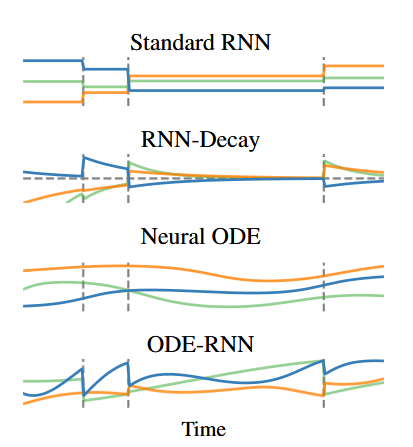

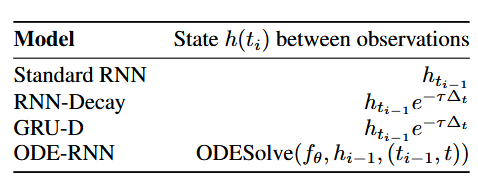

Figure and Table embedded from *Yulia Rubanova, Ricky T. Q. Chen, David Duvenaud, Latent ODEs for Irregularly-Sampled Time Series, 2019  https://arxiv.org/abs/1907.03907*

*Figure 1: Hidden state trajectories. Ver-
tical lines show observation times. Lines
show different dimensions of the hidden
state. Standard RNNs have constant or
undefined hidden states between observa-
tions. The RNN-Decay model has states
which exponentially decay towards zero,
and are updated at observations. States
of Neural ODE follow a complex trajec-
tory but are determined by the initial state.
The ODE-RNN model has states which
obey an ODE between observations, and
are also updated at observations.*   


Table 2: Definition of hidden state h(t) between
observation times ti−1 and ti in autoregressive
models. In standard RNNs, the hidden state does
not change between updates. In ODE-RNNs,
the hidden state is defined by an ODE, and is
additionally updated by another network at each
observation.

---
---

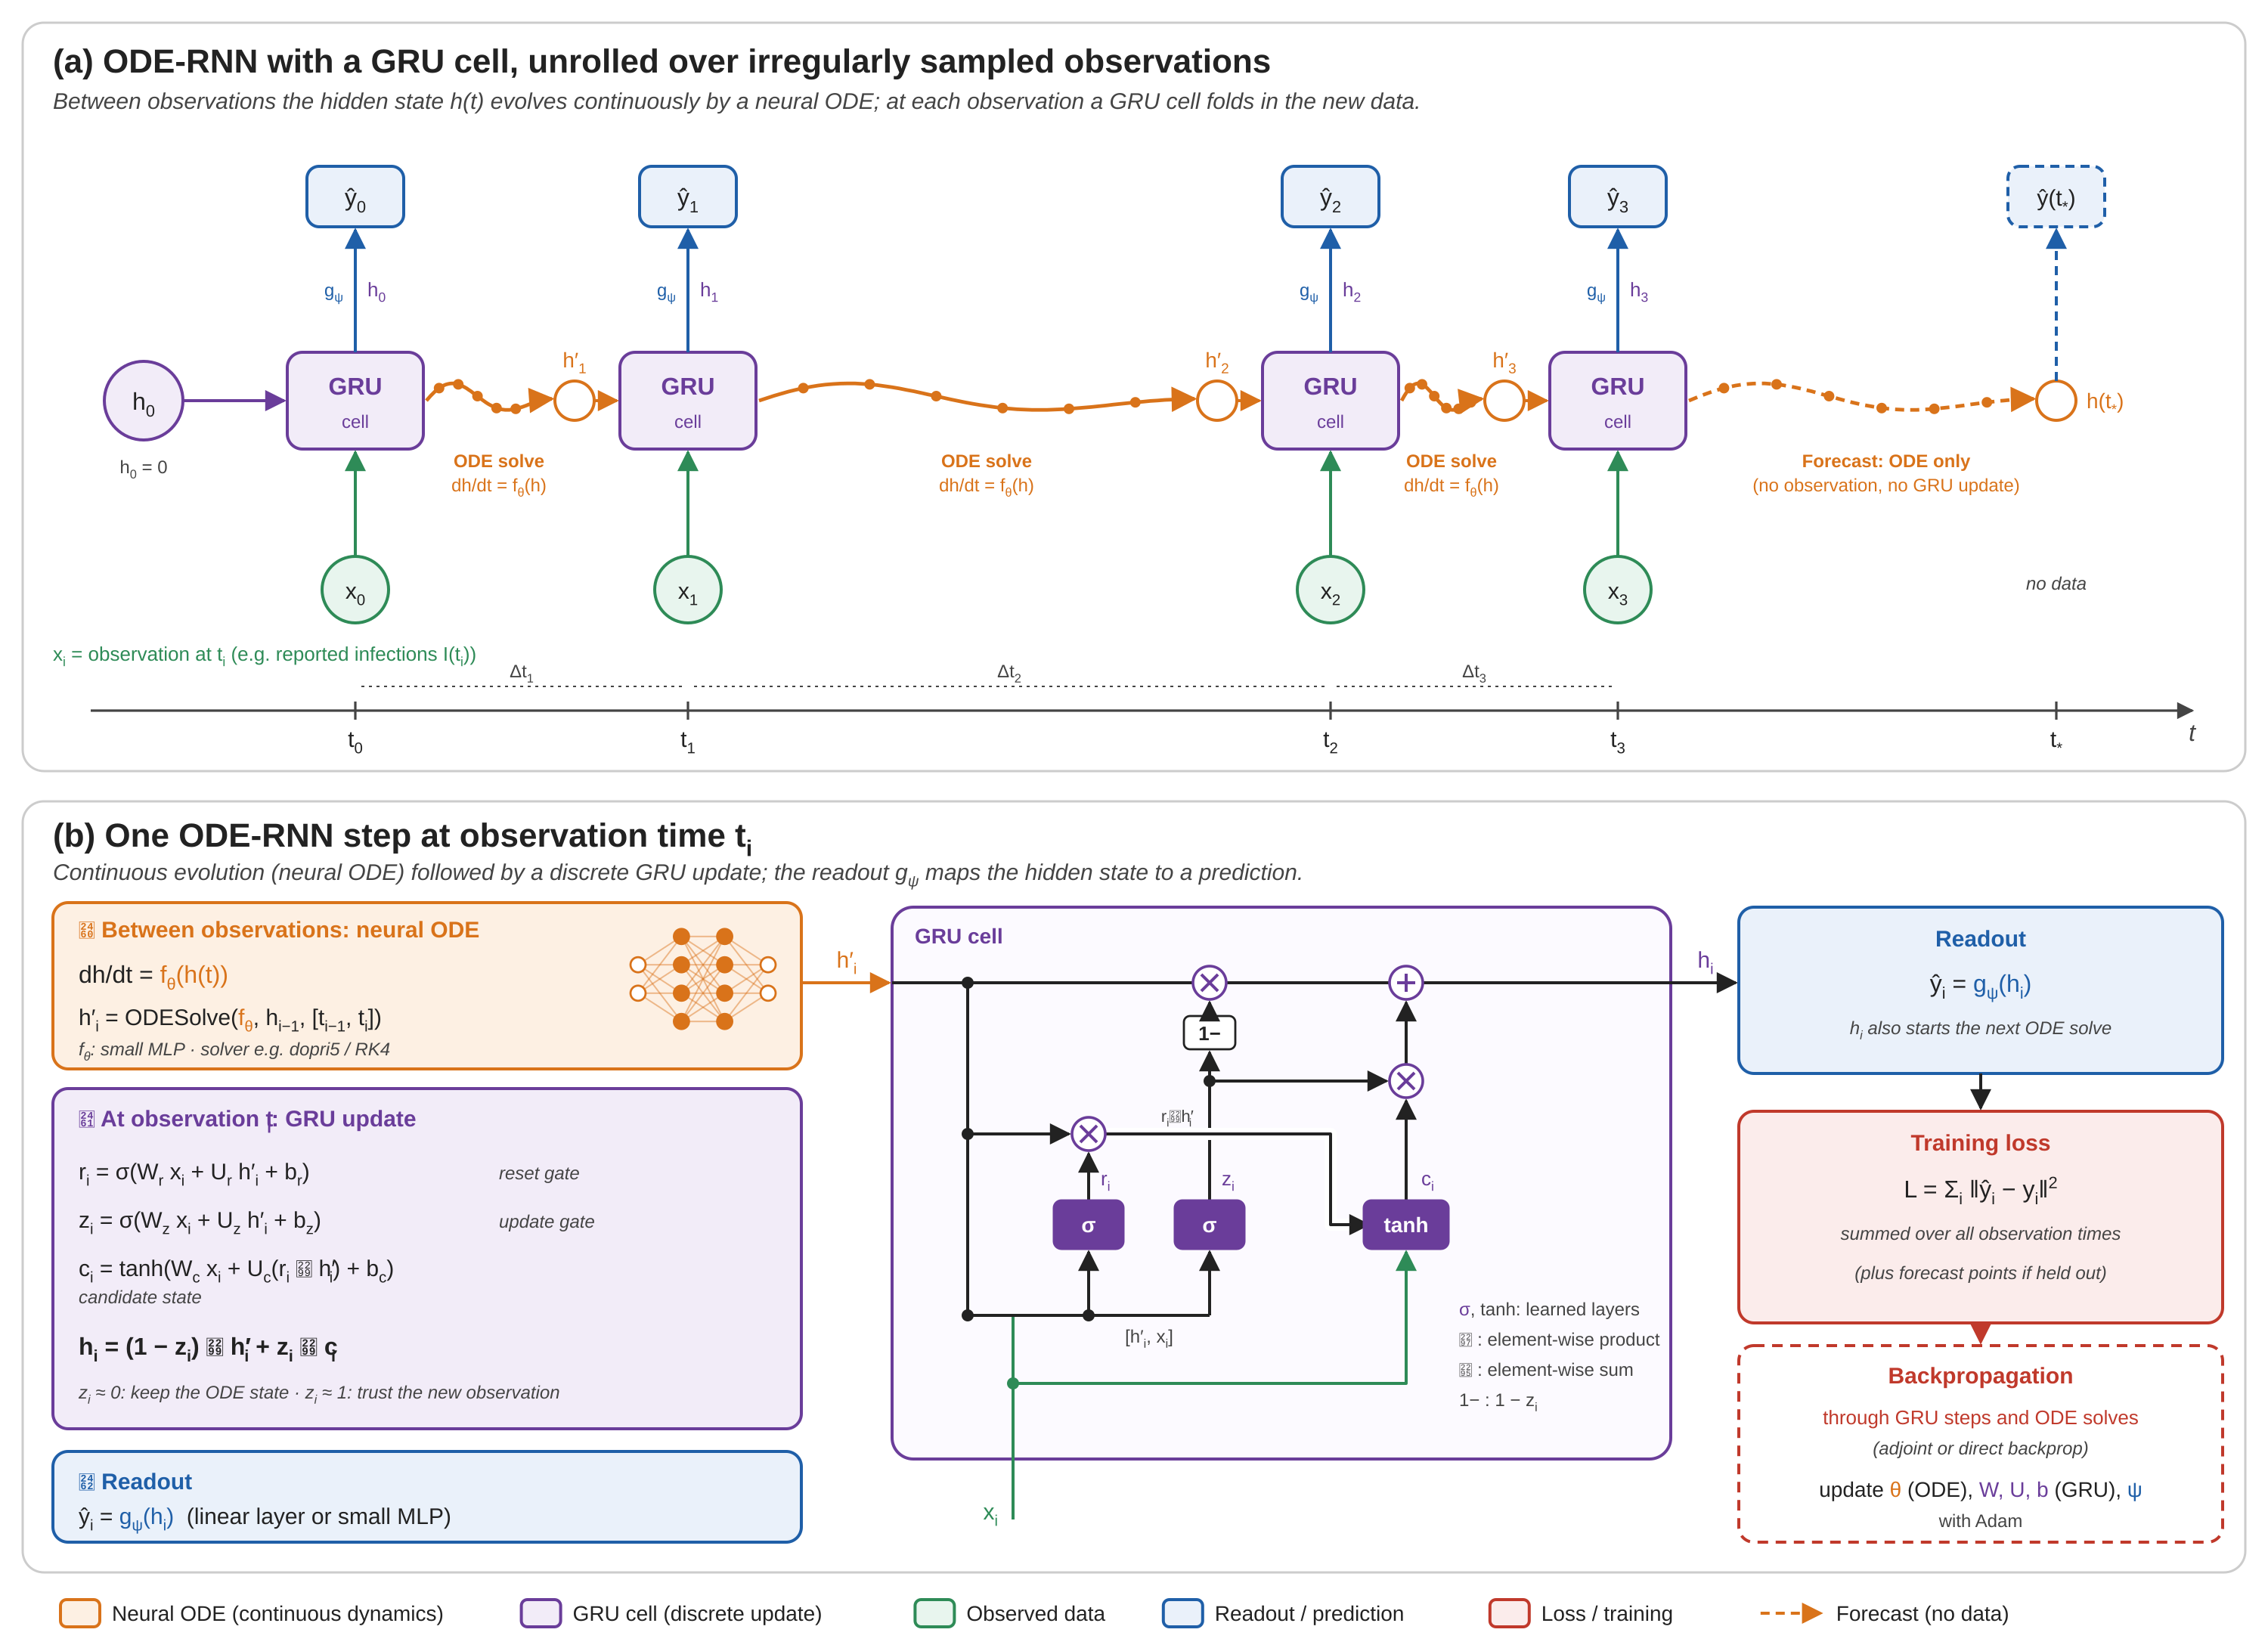

In [4]:
# @title ODE-RNN with GRU cell (figure)
import re, html
import numpy as np

W, H = 1500, 1090
FONT = "Arial, Helvetica, Liberation Sans, DejaVu Sans, sans-serif"
BLUE, BLUE_BG = "#1f5fa8", "#eaf1fa"
ORANGE, ORANGE_BG = "#d9731a", "#fdf0e3"
PURPLE, PURPLE_BG = "#6a3d9a", "#f2ecf8"
RED, RED_BG = "#c0392b", "#fbeceb"
GREEN, GREEN_BG = "#2e8b57", "#e8f5ee"
GRAY, GRAY_BG = "#444", "#f4f4f4"
INK = "#222"

out = []
def add(s): out.append(s)

def rich(s, size):
    """Mini markup: _{sub}, ^{sup}, [o]orange[/], [b]blue[/], [p]purple[/], [r]red[/], [g]green[/]."""
    toks = re.split(r'(_\{[^}]*\}|\^\{[^}]*\}|\[[obrgp]\]|\[/\])', s)
    colors = {'o': ORANGE, 'b': BLUE, 'r': RED, 'g': GREEN, 'p': PURPLE}
    res, pend, col = [], 0.0, None
    for t in toks:
        if not t: continue
        if re.fullmatch(r'\[[obrgp]\]', t): col = colors[t[1]]; continue
        if t == '[/]': col = None; continue
        fill = f' fill="{col}"' if col else ''
        if t.startswith('_{') or t.startswith('^{'):
            d = 0.28*size if t[0] == '_' else -0.38*size
            res.append(f'<tspan dy="{pend+d:.1f}" font-size="{0.68*size:.1f}"{fill}>{html.escape(t[2:-1])}</tspan>')
            pend = -d
        else:
            res.append(f'<tspan dy="{pend:.1f}"{fill}>{html.escape(t)}</tspan>')
            pend = 0.0
    return ''.join(res)

def text(x, y, s, size=15, anchor="start", weight="normal", color=INK, style="normal"):
    add(f'<text x="{x}" y="{y}" font-size="{size}" text-anchor="{anchor}" font-weight="{weight}" '
        f'font-style="{style}" fill="{color}">{rich(s, size)}</text>')

def box(x, y, w, h, stroke, fill, r=10, sw=2, dash=None):
    d = f' stroke-dasharray="{dash}"' if dash else ''
    add(f'<rect x="{x}" y="{y}" width="{w}" height="{h}" rx="{r}" fill="{fill}" stroke="{stroke}" stroke-width="{sw}"{d}/>')

def arrow(pts, color=INK, sw=2, dash=None, head=True, halo=False):
    d = f' stroke-dasharray="{dash}"' if dash else ''
    p = " ".join(f"{x:.1f},{y:.1f}" for x, y in pts)
    if halo:  # white underlay -> visible gap where this line crosses an earlier one
        add(f'<polyline points="{p}" fill="none" stroke="#fff" stroke-width="{sw+6}" stroke-linejoin="round"/>')
    m = f' marker-end="url(#ah-{color[1:]})"' if head else ''
    add(f'<polyline points="{p}" fill="none" stroke="{color}" stroke-width="{sw}" stroke-linejoin="round"{d}{m}/>')

def circle(x, y, r, stroke, fill, sw=2):
    add(f'<circle cx="{x}" cy="{y}" r="{r}" fill="{fill}" stroke="{stroke}" stroke-width="{sw}"/>')

def op(x, y, sym, color=PURPLE, r=11):
    """Pointwise operation node (⊙, +)."""
    circle(x, y, r, color, "#fff", 1.8)
    if sym == "x":
        add(f'<line x1="{x-5.5}" y1="{y-5.5}" x2="{x+5.5}" y2="{y+5.5}" stroke="{color}" stroke-width="2"/>')
        add(f'<line x1="{x-5.5}" y1="{y+5.5}" x2="{x+5.5}" y2="{y-5.5}" stroke="{color}" stroke-width="2"/>')
    else:
        add(f'<line x1="{x-6}" y1="{y}" x2="{x+6}" y2="{y}" stroke="{color}" stroke-width="2"/>')
        add(f'<line x1="{x}" y1="{y-6}" x2="{x}" y2="{y+6}" stroke="{color}" stroke-width="2"/>')

def gate(cx, cy, label, w=46, h=32, color=PURPLE):
    box(cx-w/2, cy-h/2, w, h, color, color, r=5, sw=1.5)
    text(cx, cy+5, label, 14, anchor="middle", weight="bold", color="#fff")

def nn(x, y, w, h, layers=(2, 4, 4, 2), color=ORANGE):
    xs = np.linspace(x+12, x+w-12, len(layers))
    pos = []
    for lx, n in zip(xs, layers):
        ys = np.linspace(y+h/2-(n-1)*h/(2*max(layers)), y+h/2+(n-1)*h/(2*max(layers)), n) if n > 1 else [y+h/2]
        pos.append([(lx, ly) for ly in ys])
    for a, b in zip(pos[:-1], pos[1:]):
        for p in a:
            for q in b:
                add(f'<line x1="{p[0]:.1f}" y1="{p[1]:.1f}" x2="{q[0]:.1f}" y2="{q[1]:.1f}" stroke="{color}" stroke-opacity="0.45" stroke-width="1"/>')
    for li, layer in enumerate(pos):
        for p in layer:
            f = "#fff" if li in (0, len(pos)-1) else color
            circle(round(p[0], 1), round(p[1], 1), 5, color, f, 1.4)

def ode_curve(x0, x1, y, amp=14, dashed=False):
    """Continuous hidden-state trajectory with solver-step dots."""
    xs = np.linspace(x0, x1, 60)
    ys = y - amp*np.sin(np.linspace(0, 2.2*np.pi, 60)) * np.linspace(1, 0.15, 60)
    arrow(list(zip(xs, ys)), color=ORANGE, sw=2.4, dash="6,4" if dashed else None)
    for k in range(6, 54, 9):
        circle(round(xs[k], 1), round(ys[k], 1), 3, ORANGE, ORANGE, 1)

# ---------- header ----------
add(f'<svg xmlns="http://www.w3.org/2000/svg" xml:space="preserve" width="{W}" height="{H}" viewBox="0 0 {W} {H}" font-family="{FONT}">')
add('<defs>')
for c in [INK, RED, BLUE, ORANGE, GREEN, GRAY, PURPLE]:
    add(f'<marker id="ah-{c[1:]}" viewBox="0 0 10 10" refX="9" refY="5" markerWidth="7" markerHeight="7" orient="auto-start-reverse">'
        f'<path d="M0,0 L10,5 L0,10 z" fill="{c}"/></marker>')
add('</defs>')
add(f'<rect width="{W}" height="{H}" fill="#fff"/>')

# =================== PANEL (a) unrolled ===================
add(f'<rect x="15" y="15" width="{W-30}" height="495" rx="14" fill="none" stroke="#ccc" stroke-width="1.5"/>')
text(35, 48, "(a) ODE-RNN with a GRU cell, unrolled over irregularly sampled observations", 22, weight="bold")
text(35, 72, "Between observations the hidden state h(t) evolves continuously by a neural ODE; at each observation a GRU cell folds in the new data.", 15, color=GRAY, style="italic")

ts = [235, 455, 880, 1070]        # irregular observation times (x positions)
t_fore = 1360                      # forecast time
gy, gw, gh = 265, 90, 64           # GRU box centre-y, width, height
ty = 470                           # time axis

# time axis
arrow([(60, ty), (1450, ty)], color=GRAY, sw=1.6)
text(1452, ty+20, "t", 16, anchor="end", style="italic", color=GRAY)
for i, x in enumerate(ts):
    add(f'<line x1="{x}" y1="{ty-6}" x2="{x}" y2="{ty+6}" stroke="{GRAY}" stroke-width="1.6"/>')
    text(x, ty+24, f"t_{{{i}}}", 15, anchor="middle")
add(f'<line x1="{t_fore}" y1="{ty-6}" x2="{t_fore}" y2="{ty+6}" stroke="{GRAY}" stroke-width="1.6"/>')
text(t_fore, ty+24, "t_{*}", 15, anchor="middle")
for i in range(1, len(ts)):
    a, b = ts[i-1], ts[i]
    add(f'<line x1="{a+4}" y1="{ty-16}" x2="{b-4}" y2="{ty-16}" stroke="{GRAY}" stroke-width="1" stroke-dasharray="2,3"/>')
    text((a+b)/2, ty-22, f"Δt_{{{i}}}", 12, anchor="middle", color=GRAY)

# initial hidden state
circle(95, gy, 26, PURPLE, PURPLE_BG)
text(95, gy+6, "h_{0}", 16, anchor="middle")
text(95, gy+48, "h_{0} = 0", 12, anchor="middle", color=GRAY)
arrow([(121, gy), (ts[0]-gw/2-2, gy)], color=PURPLE)

for i, x in enumerate(ts):
    # GRU cell
    box(x-gw/2, gy-gh/2, gw, gh, PURPLE, PURPLE_BG)
    text(x, gy-4, "GRU", 16, anchor="middle", weight="bold", color=PURPLE)
    text(x, gy+18, "cell", 12, anchor="middle", color=PURPLE)
    # observation input
    circle(x, 390, 22, GREEN, GREEN_BG)
    text(x, 396, f"x_{{{i}}}", 15, anchor="middle")
    arrow([(x, 368), (x, gy+gh/2+2)], color=GREEN)
    # readout
    box(x-32, 110, 64, 40, BLUE, BLUE_BG, r=8)
    text(x, 136, f"ŷ_{{{i}}}", 16, anchor="middle")
    arrow([(x, gy-gh/2), (x, 152)], color=BLUE)
    text(x+8, 196, f"h_{{{i}}}", 13, color=PURPLE)
    text(x-8, 196, "g_{ψ}", 12, anchor="end", color=BLUE)
    # ODE evolution to next observation
    if i < len(ts)-1:
        xn = ts[i+1]
        hx = xn - gw/2 - 30
        ode_curve(x+gw/2+2, hx-15, gy)
        circle(hx, gy, 13, ORANGE, "#fff")
        text(hx, gy-22, f"h′_{{{i+1}}}", 14, anchor="middle", color=ORANGE)
        arrow([(hx+13, gy), (xn-gw/2-2, gy)], color=ORANGE)
        text((x+gw/2+hx)/2, gy+44, "ODE solve", 12, anchor="middle", color=ORANGE, weight="bold")
        text((x+gw/2+hx)/2, gy+60, "dh/dt = f_{θ}(h)", 12, anchor="middle", color=ORANGE)

# forecast (ODE only, no update)
x = ts[-1]
ode_curve(x+gw/2+2, t_fore-15, gy, dashed=True)
circle(t_fore, gy, 13, ORANGE, "#fff")
text(t_fore+20, gy+5, "h(t_{*})", 14, color=ORANGE)
box(t_fore-32, 110, 64, 40, BLUE, BLUE_BG, r=8, dash="6,4")
text(t_fore, 136, "ŷ(t_{*})", 15, anchor="middle")
arrow([(t_fore, gy-13), (t_fore, 152)], color=BLUE, dash="6,4")
text((x+gw/2+t_fore)/2+10, gy+44, "Forecast: ODE only", 12, anchor="middle", color=ORANGE, weight="bold")
text((x+gw/2+t_fore)/2+10, gy+60, "(no observation, no GRU update)", 12, anchor="middle", color=ORANGE)
text(t_fore, 390, "no data", 12, anchor="middle", color=GRAY, style="italic")

text(35, 437, "x_{i} = observation at t_{i} (e.g. reported infections I(t_{i}))", 13, color=GREEN)

# =================== PANEL (b) one step ===================
oy = 530
add(f'<rect x="15" y="{oy}" width="{W-30}" height="510" rx="14" fill="none" stroke="#ccc" stroke-width="1.5"/>')
text(35, oy+30, "(b) One ODE-RNN step at observation time t_{i}", 22, weight="bold")
text(35, oy+52, "Continuous evolution (neural ODE) followed by a discrete GRU update; the readout g_{ψ} maps the hidden state to a prediction.", 15, color=GRAY, style="italic")

TOP = 650   # hidden-state line inside the cell
# step 1: ODE box
box(35, 597, 495, 110, ORANGE, ORANGE_BG)
text(52, 620, "① Between observations: neural ODE", 15, weight="bold", color=ORANGE)
text(52, 650, "dh/dt = [o]f_{θ}(h(t))[/]", 16)
text(52, 678, "h′_{i} = ODESolve([o]f_{θ}[/], h_{i−1}, [t_{i−1}, t_{i}])", 15)
text(52, 698, "f_{θ}: small MLP · solver e.g. dopri5 / RK4", 12, color=GRAY, style="italic")
nn(410, 610, 110, 75, layers=(2, 4, 4, 2))

# step 2: GRU equations
box(35, 720, 495, 225, PURPLE, PURPLE_BG)
text(52, 745, "② At observation t_{i}: GRU update", 15, weight="bold", color=PURPLE)
text(52, 780, "r_{i} = σ(W_{r} x_{i} + U_{r} h′_{i} + b_{r})", 15)
text(330, 780, "reset gate", 12, color=GRAY, style="italic")
text(52, 812, "z_{i} = σ(W_{z} x_{i} + U_{z} h′_{i} + b_{z})", 15)
text(330, 812, "update gate", 12, color=GRAY, style="italic")
text(52, 844, "c_{i} = tanh(W_{c} x_{i} + U_{c}(r_{i} ⊙ h′_{i}) + b_{c})", 15)
text(52, 862, "candidate state", 12, color=GRAY, style="italic")
text(52, 896, "h_{i} = (1 − z_{i}) ⊙ h′_{i} + z_{i} ⊙ c_{i}", 16, weight="bold")
text(52, 925, "z_{i} ≈ 0: keep the ODE state · z_{i} ≈ 1: trust the new observation", 12, color=GRAY, style="italic")

# step 3 readout (small, under the equations)
box(35, 960, 495, 60, BLUE, BLUE_BG)
text(52, 985, "③ Readout", 15, weight="bold", color=BLUE)
text(52, 1008, "ŷ_{i} = [b]g_{ψ}(h_{i})[/]  (linear layer or small MLP)", 15)

# ---------- GRU cell diagram ----------
cx0, cx1, cy0, cy1 = 590, 1105, 600, 965
box(cx0, cy0, cx1-cx0, cy1-cy0, PURPLE, "#fcfaff", r=14)
text(cx0+15, cy0+24, "GRU cell", 14, weight="bold", color=PURPLE)

xH = 640    # x of h' drop line
xX = 670    # x of input entry
BUS = 870   # concat bus
XL = 915    # separate x line feeding tanh
xR, xZ, xC = 720, 800, 930
GY = 810    # gate centres
MR = 750    # y of r ⊙ h' node
JZ = 715    # junction y for z
x1m, xplus = xZ, xC   # top-line nodes

# h' from step 1 into the cell top line
arrow([(530, TOP), (cx0-2, TOP)], color=ORANGE)
text(560, TOP-10, "h′_{i}", 15, anchor="middle", color=ORANGE)

# top line: h' -> ⊗(1-z) -> + -> h_i
arrow([(cx0, TOP), (x1m-11, TOP)], color=INK, head=False)
arrow([(x1m+11, TOP), (xplus-11, TOP)], color=INK, head=False)
arrow([(xplus+11, TOP), (1148, TOP)], color=INK)
text(1128, TOP-10, "h_{i}", 15, anchor="middle", color=PURPLE)

# h' drops to the bus; x enters from below
arrow([(xH, TOP), (xH, BUS)], color=INK, head=False)
arrow([(xX, 1005), (xX, BUS)], color=GREEN, head=False)
text(xX-10, 1005, "x_{i}", 15, anchor="end", color=GREEN)
arrow([(xH, BUS), (xZ, BUS)], color=INK, head=False)
text(760, BUS+18, "[h′_{i}, x_{i}]", 12, anchor="middle", color=GRAY)
# separate x line to tanh
arrow([(xX, XL), (xC, XL), (xC, GY+18)], color=GREEN)
circle(xX, XL, 3.5, GREEN, GREEN, 1)

# bus -> gates
arrow([(xR, BUS), (xR, GY+18)], color=INK)
arrow([(xZ, BUS), (xZ, GY+18)], color=INK)
for jx in (xH, xR):
    circle(jx, BUS, 3.5, INK, INK, 1)
circle(xH, MR, 3.5, INK, INK, 1)
circle(xH, TOP, 3.5, INK, INK, 1)

# r gate -> r ⊙ h'
arrow([(xR, GY-16), (xR, MR+13)], color=INK)
arrow([(xH, MR), (xR-13, MR)], color=INK)
text(xR+8, GY-26, "r_{i}", 13, color=PURPLE)

# z gate -> (1 - z) -> ⊗ on the top line ; z -> ⊗ with candidate
arrow([(xZ, GY-16), (xZ, JZ)], color=INK, head=False)
circle(xZ, JZ, 3.5, INK, INK, 1)
box(xZ-17, 672, 34, 22, INK, "#fff", r=4, sw=1.4)
text(xZ, 688, "1−", 13, anchor="middle", weight="bold")
arrow([(xZ, JZ), (xZ, 696)], color=INK)
arrow([(xZ, 672), (xZ, TOP+13)], color=INK)
arrow([(xZ, JZ), (xC-13, JZ)], color=INK)
text(xZ+8, GY-26, "z_{i}", 13, color=PURPLE)

# r⊙h' -> tanh (crosses z line -> halo)
arrow([(xR+11, MR), (xC-50, MR), (xC-50, GY), (xC-25, GY)], color=INK, halo=True)
text((xR+xZ)/2+18, MR-8, "r_{i}⊙h′_{i}", 11, anchor="middle", color=GRAY)

# candidate -> ⊗ with z -> + on top line
arrow([(xC, GY-16), (xC, JZ+13)], color=INK)
text(xC+10, GY-26, "c_{i}", 13, color=PURPLE)
arrow([(xC, JZ-11), (xC, TOP+13)], color=INK)

# nodes and gates on top
op(xR, MR, "x"); op(x1m, TOP, "x"); op(xC, JZ, "x"); op(xplus, TOP, "+")
gate(xR, GY, "σ"); gate(xZ, GY, "σ"); gate(xC, GY, "tanh", w=56)

# small legend inside cell
text(965, 870, "[p]σ[/], tanh: learned layers", 12, color=GRAY)
text(965, 890, "⊗ : element-wise product", 12, color=GRAY)
text(965, 910, "⊕ : element-wise sum", 12, color=GRAY)
text(965, 930, "1− : 1 − z_{i}", 12, color=GRAY)

# ---------- readout + training ----------
box(1150, 600, 320, 110, BLUE, BLUE_BG)
text(1310, 626, "Readout", 15, anchor="middle", weight="bold", color=BLUE)
text(1310, 656, "ŷ_{i} = [b]g_{ψ}(h_{i})[/]", 16, anchor="middle")
text(1310, 684, "h_{i} also starts the next ODE solve", 12, anchor="middle", color=GRAY, style="italic")

box(1150, 735, 320, 140, RED, RED_BG)
text(1310, 761, "Training loss", 15, anchor="middle", weight="bold", color=RED)
text(1310, 792, "L = Σ_{i} ‖ŷ_{i} − y_{i}‖^{2}", 16, anchor="middle")
text(1310, 820, "summed over all observation times", 12, anchor="middle", color=GRAY, style="italic")
text(1310, 846, "(plus forecast points if held out)", 12, anchor="middle", color=GRAY, style="italic")
arrow([(1310, 710), (1310, 733)], color=INK)

box(1150, 890, 320, 130, RED, "#fff", dash="7,5")
text(1310, 915, "Backpropagation", 15, anchor="middle", weight="bold", color=RED)
text(1310, 942, "through GRU steps and ODE solves", 13, anchor="middle", color=RED)
text(1310, 962, "(adjoint or direct backprop)", 12, anchor="middle", color=GRAY, style="italic")
text(1310, 990, "update [o]θ[/] (ODE), [p]W, U, b[/] (GRU), [b]ψ[/]", 14, anchor="middle")
text(1310, 1010, "with Adam", 12, anchor="middle", color=GRAY)
arrow([(1310, 875), (1310, 888)], color=RED, dash="4,3")

# =================== legend ===================
ly0 = 1058
items = [(ORANGE, ORANGE_BG, "Neural ODE (continuous dynamics)"), (PURPLE, PURPLE_BG, "GRU cell (discrete update)"),
         (GREEN, GREEN_BG, "Observed data"), (BLUE, BLUE_BG, "Readout / prediction"), (RED, RED_BG, "Loss / training")]
x = 40
for st, fi, lab in items:
    box(x, ly0, 26, 18, st, fi, r=4)
    text(x+34, ly0+14, lab, 14)
    x += 34 + len(lab)*7.4 + 34
arrow([(x, ly0+9), (x+40, ly0+9)], color=ORANGE, dash="6,4")
text(x+50, ly0+14, "Forecast (no data)", 14)

add('</svg>')
svg_str = "\n".join(out)

# ---------- render to PNG and display (Colab; also shows on GitHub after saving) ----------
import os, shutil, subprocess
from IPython.display import Image, SVG, display

with open("odernn_gru.svg", "w", encoding="utf-8") as f:
    f.write(svg_str)

if shutil.which("rsvg-convert") is None:          # Colab: install the SVG renderer once
    subprocess.run("apt-get -qq install -y librsvg2-bin > /dev/null", shell=True)

if shutil.which("rsvg-convert"):
    subprocess.run(["rsvg-convert", "-z", "2", "odernn_gru.svg", "-o", "odernn_gru.png"], check=True)
    display(Image("odernn_gru.png", width=1000))
else:                                              # fallback: browser renders the SVG
    display(SVG(svg_str))

# VI. ODE-RNN Formulation (Algorithm 1 — copied from Rubanova et al., 2019)

---
**Algorithm 1** The ODE-RNN. The only difference, highlighted in yellow, from standard RNNs is that the pre-activations $h'$ evolve according to an ODE between observations, instead of being fixed.

---

**Input:** Data points and their timestamps $\{(x_i, t_i)\}_{i=1..N}$  
1: $h_0 = \mathbf{0}$  
2: **for** $i$ in $1, 2, \dots, N$ **do**  
3: $\quad \color{yellow}{h'_i = \text{ODESolve}(f_\theta, h_{i-1}, (t_{i-1}, t_i))}$ $\qquad\triangleright$ Solve ODE to get state at $t_i$  
4: $\quad h_i = \text{RNNCell}(h'_i, x_i)$ $\qquad\qquad\qquad\qquad\triangleright$ Update hidden state given current observation $x_i$  
5: **end for**  
6: $o_i = \text{OutputNN}(h_i)$ for all $i = 1..N$  
**Return:** $\{o_i\}_{i=1..N}; \, h_N$

---



Epoch  50 | MSE Loss: 0.08209
Epoch 100 | MSE Loss: 0.06482
Epoch 150 | MSE Loss: 0.03987
Epoch 200 | MSE Loss: 0.03012
Epoch 250 | MSE Loss: 0.02297


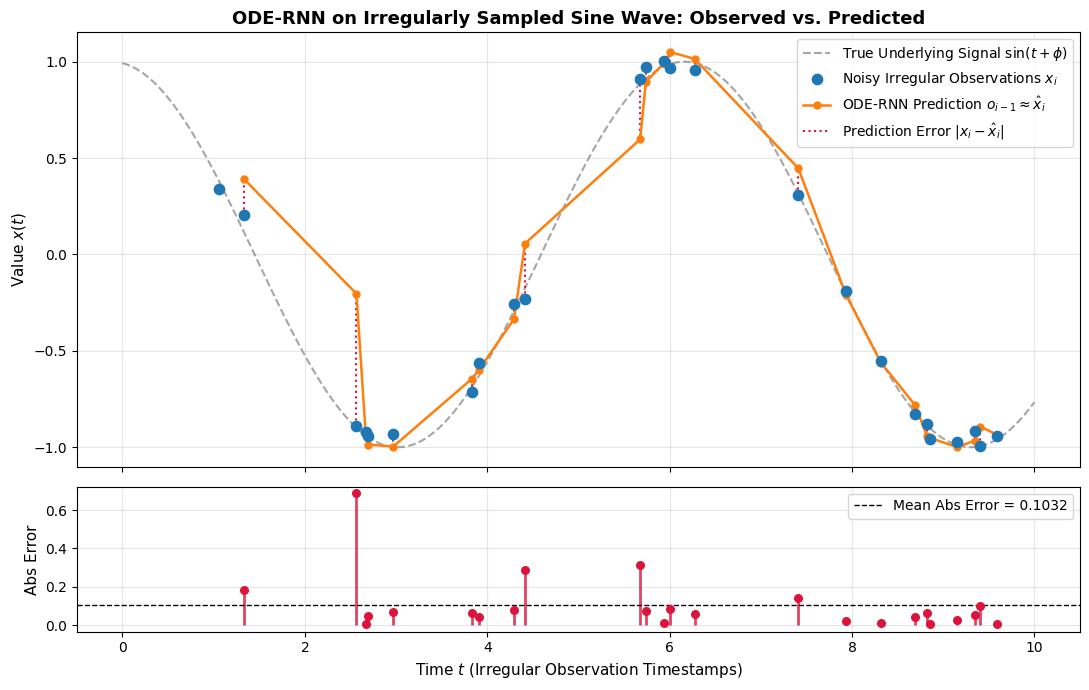

In [ ]:
!pip install torchdiffeq
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from torchdiffeq import odeint

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# ---------------------------------------------------------
# 1. Define the continuous dynamics f_theta(t, h)
# ---------------------------------------------------------
class ODEFunc(nn.Module):
    def __init__(self, hidden_dim):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(hidden_dim, hidden_dim),
            nn.Tanh(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.Tanh(),
        )

    def forward(self, t, h):
        return self.net(h)


# ---------------------------------------------------------
# 2. ODE-RNN Module (Matches Algorithm 1)
# ---------------------------------------------------------
class ODERNN(nn.Module):
    def __init__(self, input_dim, hidden_dim, output_dim):
        super().__init__()
        self.hidden_dim = hidden_dim
        self.f_theta = ODEFunc(hidden_dim)
        self.rnn_cell = nn.GRUCell(input_dim, hidden_dim)
        self.output_nn = nn.Linear(hidden_dim, output_dim)

    def forward(self, x, t):
        batch_size, N, _ = x.shape
        h = torch.zeros(batch_size, self.hidden_dim, device=x.device)
        outputs = []

        for i in range(N):
            if i == 0:
                h_prime = h
            else:
                t_span = torch.stack([t[i - 1], t[i]])
                h_traj = odeint(self.f_theta, h, t_span, method="rk4")
                h_prime = h_traj[-1]

            h = self.rnn_cell(x[:, i, :], h_prime)
            o_i = self.output_nn(h)
            outputs.append(o_i)

        outputs = torch.stack(outputs, dim=1)
        return outputs, h


# ---------------------------------------------------------
# 3. Toy Example: Irregularly Sampled Sine Wave
# ---------------------------------------------------------
torch.manual_seed(42)

batch_size = 32
N = 25          # Number of irregular observations
input_dim = 1
hidden_dim = 16
output_dim = 1

# Generate irregular timestamps in [0, 10]
t = torch.sort(torch.rand(N) * 10.0)[0].to(device)

# Generate noisy sine waves with random phase shifts: x(t) = sin(t + phase)
phases = torch.rand(batch_size, 1, 1, device=device) * 2 * torch.pi
clean_signal = torch.sin(t.view(1, N, 1) + phases)
x_obs = clean_signal + 0.05 * torch.randn_like(clean_signal)

# Train ODE-RNN to predict next observation x_{i+1} from history up to t_i
model = ODERNN(input_dim, hidden_dim, output_dim).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-2)
loss_fn = nn.MSELoss()

for epoch in range(1, 251):
    optimizer.zero_grad()
    o_pred, h_N = model(x_obs[:, :-1, :], t[:-1])
    loss = loss_fn(o_pred, x_obs[:, 1:, :])
    loss.backward()
    optimizer.step()

    if epoch % 50 == 0:
        print(f"Epoch {epoch:3d} | MSE Loss: {loss.item():.5f}")

# ---------------------------------------------------------
# 4. Plot: Observed vs. Predicted & Residual Differences
# ---------------------------------------------------------
model.eval()
with torch.no_grad():
    o_pred, _ = model(x_obs[:, :-1, :], t[:-1])

# Pick sample 0 from the batch to visualize
sample_idx = 0
t_np = t.cpu().numpy()
phase_0 = phases[sample_idx].item()
x_obs_np = x_obs[sample_idx, :, 0].cpu().numpy()
o_pred_np = o_pred[sample_idx, :, 0].cpu().numpy()

# Dense grid for true underlying continuous sine wave
t_dense = torch.linspace(0, 10, 300).numpy()
true_dense = torch.sin(torch.tensor(t_dense) + phase_0).numpy()

# Target timestamps and values (t_1 to t_{N-1})
t_target = t_np[1:]
x_target = x_obs_np[1:]
abs_errors = abs(x_target - o_pred_np)

fig, (ax1, ax2) = plt.subplots(
    2, 1, figsize=(11, 7), sharex=True, gridspec_kw={"height_ratios": (3, 1)}
)

# --- Top Panel: Trajectory & Error Bars ---
ax1.plot(t_dense, true_dense, "--", color="gray", alpha=0.7, label="True Underlying Signal $\\sin(t + \\phi)$")
ax1.scatter(t_np, x_obs_np, color="#1f77b4", s=55, zorder=4, label="Noisy Irregular Observations $x_i$")
ax1.plot(t_target, o_pred_np, "-o", color="#ff7f0e", markersize=5, linewidth=1.8, zorder=3, label="ODE-RNN Prediction $o_{i-1} \\approx \\hat{x}_i$")

# Draw vertical red lines highlighting prediction error at each observation
for ti, yi_true, yi_pred in zip(t_target, x_target, o_pred_np):
    ax1.plot([ti, ti], [yi_true, yi_pred], color="crimson", linestyle=":", linewidth=1.5, zorder=2)

# Dummy line for legend
ax1.plot([], [], color="crimson", linestyle=":", linewidth=1.5, label="Prediction Error $|x_i - \\hat{x}_i|$")

ax1.set_ylabel("Value $x(t)$", fontsize=11)
ax1.set_title("ODE-RNN on Irregularly Sampled Sine Wave: Observed vs. Predicted", fontsize=13, fontweight="bold")
ax1.legend(loc="upper right", frameon=True)
ax1.grid(True, alpha=0.3)

# --- Bottom Panel: Absolute Error Over Time ---
ax2.vlines(t_target, 0, abs_errors, color="crimson", linewidth=2, alpha=0.8)
ax2.scatter(t_target, abs_errors, color="crimson", s=30, zorder=3)
ax2.axhline(abs_errors.mean(), color="black", linestyle="--", linewidth=1, label=f"Mean Abs Error = {abs_errors.mean():.4f}")

ax2.set_xlabel("Time $t$ (Irregular Observation Timestamps)", fontsize=11)
ax2.set_ylabel("Abs Error", fontsize=11)
ax2.legend(loc="upper right", frameon=True)
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


# VII. Latent ODE overview

### Overview of Latent Neural ODE and limitations

A Latent ODE frames continuous-time dynamics within an encoder-decoder setup. It encodes all incoming historical time-series data into an initial condition, then allows that state to evolve autonomously in a low-dimensional latent space.

Mechanism: An encoder (such as an RNN or ODE-RNN) processes observations at irregular intervals. It outputs a distribution for the initial latent state z₀.

A decoder then uses an ODE solver to evolve z₀ continuously forward in time.

Core Equation: Governed strictly by an autonomous differential equation: $\frac{dz(t)}{dt} = f_\theta(z(t), x(t))$.

Strengths: Excels at generative tasks and data imputation (filling in missing gaps), and outputs an explicit measure of uncertainty (due to the probabilistic VAE framework).

Limitations: Because the ODE trajectory is driven solely by the initial state z₀, later observations cannot directly steer or influence the path without explicitly resetting/updating the state.


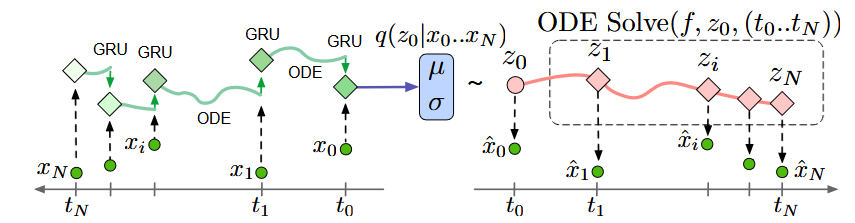

*Figure 2: The Latent ODE model with an ODE-RNN encoder. To make predictions in this model, the ODE-RNN encoder is run backwards in time to produce an approximate posterior over the initial state: $q(z_0|({x_i, t_i)}^N_{i=0})$ Given a sample of $z_0$, we can find the latent state at any point of interest by solving an ODE initial-value problem.*

Figure and Table embedded from *Yulia Rubanova, Ricky T. Q. Chen, David Duvenaud, Latent ODEs for Irregularly-Sampled Time Series, 2019  https://arxiv.org/abs/1907.03907*




---
---

## Additional info to know for Variational Auto-Encoders (VAE)  (Latent ODEs are based on VAE)

## Use of ELBO (Evidence Lower Bound) Loss

**ELBO loss** is the negative Evidence Lower Bound used to train latent variable models (auto-encoder models) which involves maximizing log-likelihood $\log p(x)$. However, as they are intractable to compute directly, instead of maximizing $\log p(x)$ directly, we maximize the ELBO—or equivalently, minimize its negative—using variational inference.

### Mathematical Formulation

$$\mathcal{L}_{\text{ELBO}} = -\mathbb{E}_{q_\phi(z|x)}\big[\log p_\theta(x|z)\big] + D_{\text{KL}}\big(q_\phi(z|x) \,\|\, p(z)\big)$$

* **Reconstruction Loss** ($-\mathbb{E}_{q_\phi(z|x)}[\log p_\theta(x|z)]$): Measures how well the decoder $p_\theta(x|z)$ reconstructs the input $x$ from the latent variable $z$.
* **KL Divergence Regularization** ($D_{\text{KL}}(q_\phi(z|x) \,\|\, p(z))$): Penalizes the approximate posterior $q_\phi(z|x)$ for diverging from the prior $p(z)$ (typically $\mathcal{N}(0, I)$), keeping the latent space smooth and continuous.







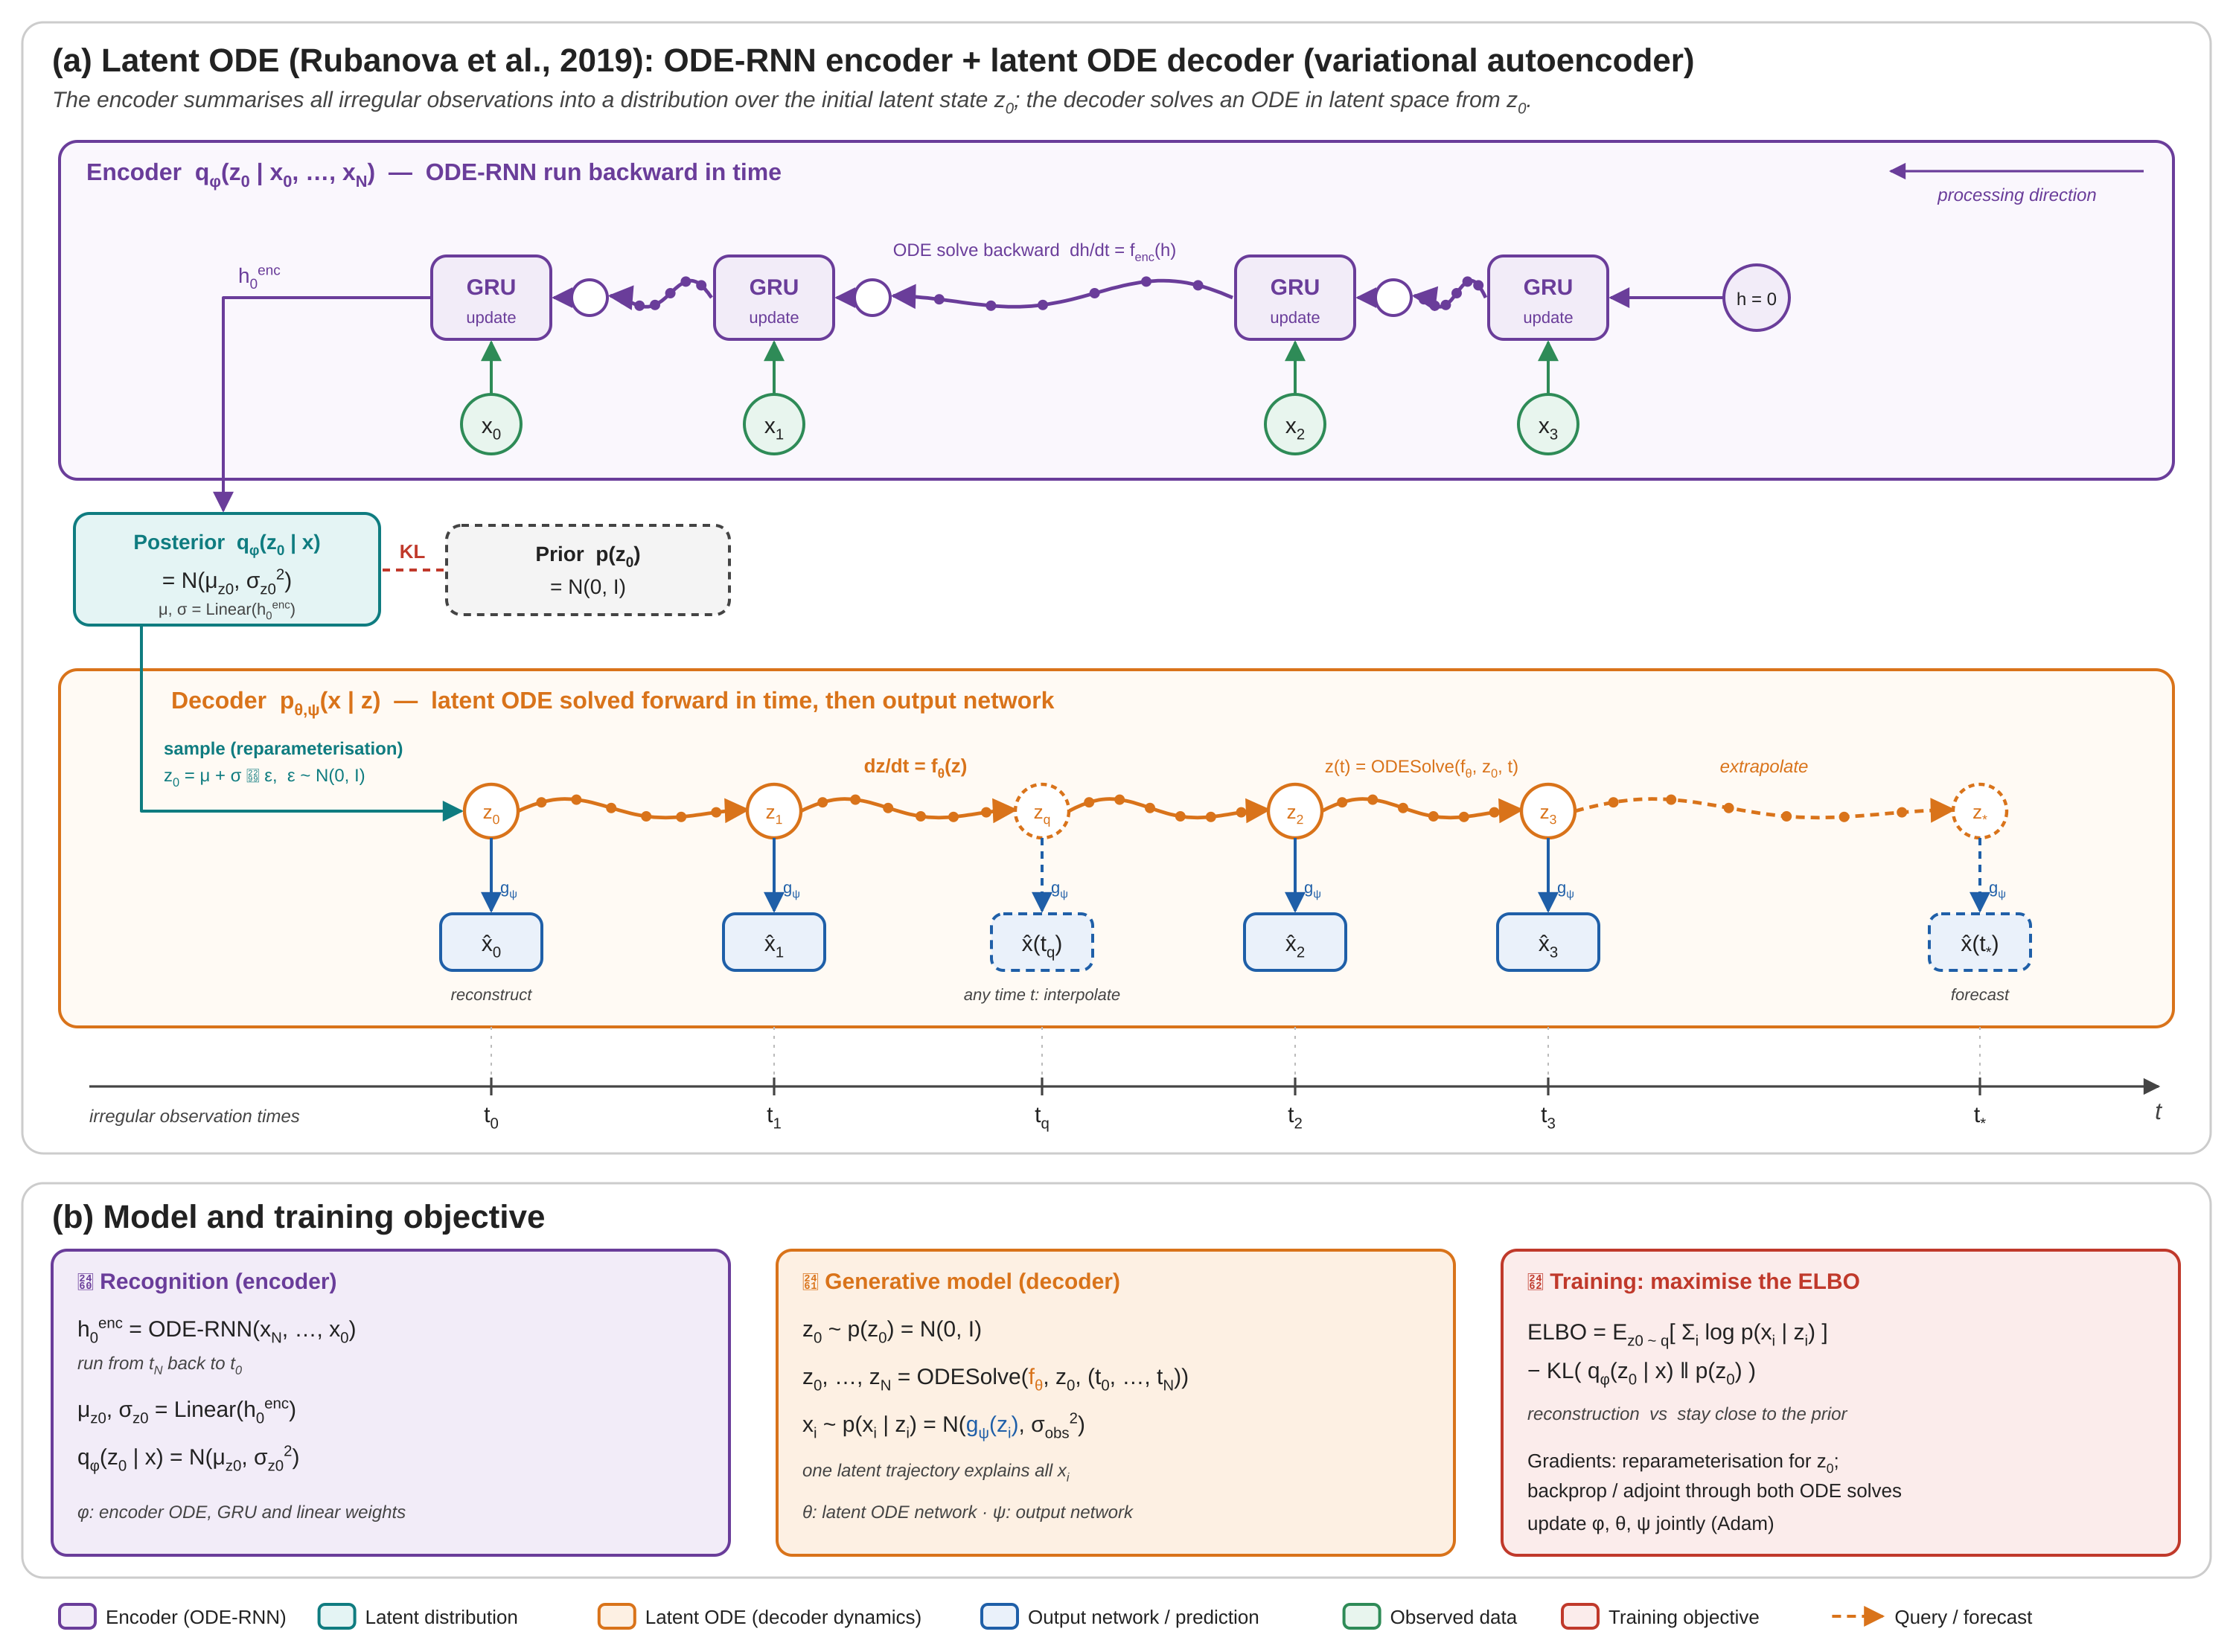

In [5]:
# @title Latent ODE (Rubanova et al., 2019) figure
import re, html
import numpy as np

W, H = 1500, 1110
FONT = "Arial, Helvetica, Liberation Sans, DejaVu Sans, sans-serif"
BLUE, BLUE_BG = "#1f5fa8", "#eaf1fa"
ORANGE, ORANGE_BG = "#d9731a", "#fdf0e3"
PURPLE, PURPLE_BG = "#6a3d9a", "#f2ecf8"
RED, RED_BG = "#c0392b", "#fbeceb"
GREEN, GREEN_BG = "#2e8b57", "#e8f5ee"
GRAY, GRAY_BG = "#444", "#f4f4f4"
TEAL, TEAL_BG = "#0f7c80", "#e4f4f4"
INK = "#222"

out = []
def add(s): out.append(s)

def rich(s, size):
    """Mini markup: _{sub}, ^{sup}, [o]orange[/], [b]blue[/], [p]purple[/], [r]red[/], [g]green[/]."""
    toks = re.split(r'(_\{[^}]*\}|\^\{[^}]*\}|\[[obrgpt]\]|\[/\])', s)
    colors = {'o': ORANGE, 'b': BLUE, 'r': RED, 'g': GREEN, 'p': PURPLE, 't': TEAL}
    res, pend, col = [], 0.0, None
    for t in toks:
        if not t: continue
        if re.fullmatch(r'\[[obrgpt]\]', t): col = colors[t[1]]; continue
        if t == '[/]': col = None; continue
        fill = f' fill="{col}"' if col else ''
        if t.startswith('_{') or t.startswith('^{'):
            d = 0.28*size if t[0] == '_' else -0.38*size
            res.append(f'<tspan dy="{pend+d:.1f}" font-size="{0.68*size:.1f}"{fill}>{html.escape(t[2:-1])}</tspan>')
            pend = -d
        else:
            res.append(f'<tspan dy="{pend:.1f}"{fill}>{html.escape(t)}</tspan>')
            pend = 0.0
    return ''.join(res)

def text(x, y, s, size=15, anchor="start", weight="normal", color=INK, style="normal"):
    add(f'<text x="{x}" y="{y}" font-size="{size}" text-anchor="{anchor}" font-weight="{weight}" '
        f'font-style="{style}" fill="{color}">{rich(s, size)}</text>')

def box(x, y, w, h, stroke, fill, r=10, sw=2, dash=None):
    d = f' stroke-dasharray="{dash}"' if dash else ''
    add(f'<rect x="{x}" y="{y}" width="{w}" height="{h}" rx="{r}" fill="{fill}" stroke="{stroke}" stroke-width="{sw}"{d}/>')

def arrow(pts, color=INK, sw=2, dash=None, head=True, halo=False):
    d = f' stroke-dasharray="{dash}"' if dash else ''
    p = " ".join(f"{x:.1f},{y:.1f}" for x, y in pts)
    if halo:  # white underlay -> visible gap where this line crosses an earlier one
        add(f'<polyline points="{p}" fill="none" stroke="#fff" stroke-width="{sw+6}" stroke-linejoin="round"/>')
    m = f' marker-end="url(#ah-{color[1:]})"' if head else ''
    add(f'<polyline points="{p}" fill="none" stroke="{color}" stroke-width="{sw}" stroke-linejoin="round"{d}{m}/>')

def circle(x, y, r, stroke, fill, sw=2):
    add(f'<circle cx="{x}" cy="{y}" r="{r}" fill="{fill}" stroke="{stroke}" stroke-width="{sw}"/>')

def op(x, y, sym, color=PURPLE, r=11):
    """Pointwise operation node (⊙, +)."""
    circle(x, y, r, color, "#fff", 1.8)
    if sym == "x":
        add(f'<line x1="{x-5.5}" y1="{y-5.5}" x2="{x+5.5}" y2="{y+5.5}" stroke="{color}" stroke-width="2"/>')
        add(f'<line x1="{x-5.5}" y1="{y+5.5}" x2="{x+5.5}" y2="{y-5.5}" stroke="{color}" stroke-width="2"/>')
    else:
        add(f'<line x1="{x-6}" y1="{y}" x2="{x+6}" y2="{y}" stroke="{color}" stroke-width="2"/>')
        add(f'<line x1="{x}" y1="{y-6}" x2="{x}" y2="{y+6}" stroke="{color}" stroke-width="2"/>')

def gate(cx, cy, label, w=46, h=32, color=PURPLE):
    box(cx-w/2, cy-h/2, w, h, color, color, r=5, sw=1.5)
    text(cx, cy+5, label, 14, anchor="middle", weight="bold", color="#fff")

def nn(x, y, w, h, layers=(2, 4, 4, 2), color=ORANGE):
    xs = np.linspace(x+12, x+w-12, len(layers))
    pos = []
    for lx, n in zip(xs, layers):
        ys = np.linspace(y+h/2-(n-1)*h/(2*max(layers)), y+h/2+(n-1)*h/(2*max(layers)), n) if n > 1 else [y+h/2]
        pos.append([(lx, ly) for ly in ys])
    for a, b in zip(pos[:-1], pos[1:]):
        for p in a:
            for q in b:
                add(f'<line x1="{p[0]:.1f}" y1="{p[1]:.1f}" x2="{q[0]:.1f}" y2="{q[1]:.1f}" stroke="{color}" stroke-opacity="0.45" stroke-width="1"/>')
    for li, layer in enumerate(pos):
        for p in layer:
            f = "#fff" if li in (0, len(pos)-1) else color
            circle(round(p[0], 1), round(p[1], 1), 5, color, f, 1.4)

def ode_curve(x0, x1, y, amp=14, dashed=False, color=ORANGE, head=True):
    """Continuous trajectory with solver-step dots (x1 < x0 draws it right-to-left)."""
    xs = np.linspace(x0, x1, 60)
    ys = y - amp*np.sin(np.linspace(0, 2.2*np.pi, 60)) * np.linspace(1, 0.15, 60)
    arrow(list(zip(xs, ys)), color=color, sw=2.4, dash="6,4" if dashed else None, head=head)
    for k in range(6, 54, 9):
        circle(round(xs[k], 1), round(ys[k], 1), 3, color, color, 1)

# ---------- header ----------
add(f'<svg xmlns="http://www.w3.org/2000/svg" xml:space="preserve" width="{W}" height="{H}" viewBox="0 0 {W} {H}" font-family="{FONT}">')
add('<defs>')
for c in [INK, RED, BLUE, ORANGE, GREEN, GRAY, PURPLE, TEAL]:
    add(f'<marker id="ah-{c[1:]}" viewBox="0 0 10 10" refX="9" refY="5" markerWidth="7" markerHeight="7" orient="auto-start-reverse">'
        f'<path d="M0,0 L10,5 L0,10 z" fill="{c}"/></marker>')
add('</defs>')
add(f'<rect width="{W}" height="{H}" fill="#fff"/>')

# =================== PANEL (a) architecture ===================
add(f'<rect x="15" y="15" width="{W-30}" height="760" rx="14" fill="none" stroke="#ccc" stroke-width="1.5"/>')
text(35, 48, "(a) Latent ODE (Rubanova et al., 2019): ODE-RNN encoder + latent ODE decoder (variational autoencoder)", 22, weight="bold")
text(35, 72, "The encoder summarises all irregular observations into a distribution over the initial latent state z_{0}; the decoder solves an ODE in latent space from z_{0}.", 15, color=GRAY, style="italic")

ts = [330, 520, 870, 1040]   # observation times
tq, tstar = 700, 1330        # query (interpolation) and forecast (extrapolation) times
names = ["t_{0}", "t_{1}", "t_{2}", "t_{3}"]

# ---------- encoder band ----------
EY0, EY1, EG = 95, 322, 200     # band top/bottom, GRU centre-y
box(40, EY0, 1420, EY1-EY0, PURPLE, "#faf7fd", r=12)
text(58, EY0+26, "Encoder  q_{φ}(z_{0} | x_{0}, …, x_{N})  —  ODE-RNN run backward in time", 16, weight="bold", color=PURPLE)
arrow([(1440, EY0+20), (1270, EY0+20)], color=PURPLE, sw=1.6)
text(1355, EY0+40, "processing direction", 12, anchor="middle", color=PURPLE, style="italic")

gw, gh = 80, 56
# start state at the far right (after the last observation)
circle(1180, EG, 22, PURPLE, PURPLE_BG)
text(1180, EG+5, "h = 0", 12, anchor="middle")
arrow([(1158, EG), (ts[-1]+gw/2+2, EG)], color=PURPLE)
for i, x in enumerate(ts):
    box(x-gw/2, EG-gh/2, gw, gh, PURPLE, PURPLE_BG)
    text(x, EG-2, "GRU", 15, anchor="middle", weight="bold", color=PURPLE)
    text(x, EG+17, "update", 11, anchor="middle", color=PURPLE)
    circle(x, 285, 20, GREEN, GREEN_BG)
    text(x, 291, f"x_{{{i}}}", 15, anchor="middle")
    arrow([(x, 265), (x, EG+gh/2+2)], color=GREEN)
    if i > 0:   # ODE solve backward from t_i to t_{i-1}
        xp = ts[i-1]
        hx = xp + gw/2 + 26
        ode_curve(x-gw/2-2, hx+14, EG, color=PURPLE)
        circle(hx, EG, 12, PURPLE, "#fff")
        arrow([(hx-12, EG), (xp+gw/2+2, EG)], color=PURPLE)
        if x - xp > 250:
            text((x+xp)/2, EG-28, "ODE solve backward  dh/dt = f_{enc}(h)", 12, anchor="middle", color=PURPLE)
# encoder output -> q(z0)
QX0, QX1, QY0, QY1 = 50, 255, 345, 420
arrow([(ts[0]-gw/2, EG), (150, EG), (150, QY0-2)], color=PURPLE)
text(160, EG-10, "h_{0}^{enc}", 14, color=PURPLE)

# ---------- q(z0), prior, KL ----------
box(QX0, QY0, QX1-QX0, QY1-QY0, TEAL, TEAL_BG)
text((QX0+QX1)/2, QY0+24, "Posterior  q_{φ}(z_{0} | x)", 14, anchor="middle", weight="bold", color=TEAL)
text((QX0+QX1)/2, QY0+50, "= N(μ_{z0}, σ_{z0}^{2})", 15, anchor="middle")
text((QX0+QX1)/2, QY0+68, "μ, σ = Linear(h_{0}^{enc})", 11, anchor="middle", color=GRAY)
box(300, QY0+8, 190, 60, GRAY, GRAY_BG, dash="5,4")
text(395, QY0+32, "Prior  p(z_{0})", 14, anchor="middle", weight="bold")
text(395, QY0+54, "= N(0, I)", 14, anchor="middle")
arrow([(298, QY0+38), (QX1+2, QY0+38)], color=RED, dash="5,4", head=False)
text(277, QY0+30, "KL", 13, anchor="middle", color=RED, weight="bold")

# ---------- decoder band ----------
DY0, DY1, ZY = 450, 690, 545
box(40, DY0, 1420, DY1-DY0, ORANGE, "#fffaf4", r=12)
text(115, DY0+26, "Decoder  p_{θ,ψ}(x | z)  —  latent ODE solved forward in time, then output network", 16, weight="bold", color=ORANGE)

# sampling z0 (reparameterisation)
arrow([(95, QY1), (95, ZY), (ts[0]-20, ZY)], color=TEAL)
text(110, ZY-38, "sample (reparameterisation)", 12, color=TEAL, weight="bold")
text(110, ZY-20, "z_{0} = μ + σ ⊙ ε,  ε ~ N(0, I)", 12, color=TEAL)

# latent trajectory z(t) through all times
pts = [ts[0], ts[1], tq, ts[2], ts[3]]
for a, b in zip(pts[:-1], pts[1:]):
    ode_curve(a+18, b-18, ZY, amp=10)
ode_curve(ts[3]+18, tstar-18, ZY, amp=10, dashed=True)
text((ts[1]+tq)/2+5, ZY-26, "dz/dt = f_{θ}(z)", 13, anchor="middle", color=ORANGE, weight="bold")
text((ts[2]+ts[3])/2, ZY-26, "z(t) = ODESolve(f_{θ}, z_{0}, t)", 12, anchor="middle", color=ORANGE)
text((ts[3]+tstar)/2, ZY-26, "extrapolate", 12, anchor="middle", color=ORANGE, style="italic")

def znode(x, lab, dashed=False):
    add(f'<circle cx="{x}" cy="{ZY}" r="18" fill="#fff" stroke="{ORANGE}" stroke-width="2.2"'
        + (' stroke-dasharray="4,3"' if dashed else '') + '/>')
    text(x, ZY+5, lab, 13, anchor="middle", color=ORANGE)

def xhat(x, lab, dashed=False, note=None):
    arrow([(x, ZY+18), (x, 612)], color=BLUE, dash="5,4" if dashed else None)
    text(x+6, 600, "g_{ψ}", 11, color=BLUE)
    box(x-34, 614, 68, 38, BLUE, BLUE_BG, r=8, dash="6,4" if dashed else None)
    text(x, 639, lab, 15, anchor="middle")
    if note:
        text(x, 672, note, 11, anchor="middle", color=GRAY, style="italic")

for i, x in enumerate(ts):
    znode(x, f"z_{{{i}}}")
    xhat(x, f"x̂_{{{i}}}", note="reconstruct" if i == 0 else None)
znode(tq, "z_{q}", dashed=True); xhat(tq, "x̂(t_{q})", dashed=True, note="any time t: interpolate")
znode(tstar, "z_{*}", dashed=True); xhat(tstar, "x̂(t_{*})", dashed=True, note="forecast")

# ---------- shared time axis ----------
ty = 730
arrow([(60, ty), (1450, ty)], color=GRAY, sw=1.6)
text(1452, ty+22, "t", 16, anchor="end", style="italic", color=GRAY)
for x, lab in list(zip(ts, names)) + [(tq, "t_{q}"), (tstar, "t_{*}")]:
    add(f'<line x1="{x}" y1="{ty-6}" x2="{x}" y2="{ty+6}" stroke="{GRAY}" stroke-width="1.6"/>')
    text(x, ty+24, lab, 15, anchor="middle")
    add(f'<line x1="{x}" y1="{DY1}" x2="{x}" y2="{ty-8}" stroke="#bbb" stroke-width="1" stroke-dasharray="2,4"/>')
text(60, ty+24, "irregular observation times", 12, color=GRAY, style="italic")

# =================== PANEL (b) equations ===================
oy = 795
add(f'<rect x="15" y="{oy}" width="{W-30}" height="265" rx="14" fill="none" stroke="#ccc" stroke-width="1.5"/>')
text(35, oy+30, "(b) Model and training objective", 22, weight="bold")

bw, bh, by = 455, 205, oy+45
# encoder
box(35, by, bw, bh, PURPLE, PURPLE_BG)
text(52, by+26, "① Recognition (encoder)", 15, weight="bold", color=PURPLE)
text(52, by+58, "h_{0}^{enc} = ODE-RNN(x_{N}, …, x_{0})", 15)
text(52, by+80, "run from t_{N} back to t_{0}", 12, color=GRAY, style="italic")
text(52, by+112, "μ_{z0}, σ_{z0} = Linear(h_{0}^{enc})", 15)
text(52, by+144, "q_{φ}(z_{0} | x) = N(μ_{z0}, σ_{z0}^{2})", 15)
text(52, by+180, "φ: encoder ODE, GRU and linear weights", 12, color=GRAY, style="italic")

# generative
box(522, by, bw, bh, ORANGE, ORANGE_BG)
text(539, by+26, "② Generative model (decoder)", 15, weight="bold", color=ORANGE)
text(539, by+58, "z_{0} ~ p(z_{0}) = N(0, I)", 15)
text(539, by+90, "z_{0}, …, z_{N} = ODESolve([o]f_{θ}[/], z_{0}, (t_{0}, …, t_{N}))", 15)
text(539, by+122, "x_{i} ~ p(x_{i} | z_{i}) = N([b]g_{ψ}(z_{i})[/], σ_{obs}^{2})", 15)
text(539, by+152, "one latent trajectory explains all x_{i}", 12, color=GRAY, style="italic")
text(539, by+180, "θ: latent ODE network · ψ: output network", 12, color=GRAY, style="italic")

# training
box(1009, by, bw, bh, RED, RED_BG)
text(1026, by+26, "③ Training: maximise the ELBO", 15, weight="bold", color=RED)
text(1026, by+60, "ELBO = E_{z0 ~ q}[ Σ_{i} log p(x_{i} | z_{i}) ]", 15)
text(1026, by+86, "− KL( q_{φ}(z_{0} | x) ‖ p(z_{0}) )", 15)
text(1026, by+114, "reconstruction  vs  stay close to the prior", 12, color=GRAY, style="italic")
text(1026, by+146, "Gradients: reparameterisation for z_{0};", 13)
text(1026, by+166, "backprop / adjoint through both ODE solves", 13)
text(1026, by+188, "update φ, θ, ψ jointly (Adam)", 13)

# =================== legend ===================
ly0 = 1078
items = [(PURPLE, PURPLE_BG, "Encoder (ODE-RNN)"), (TEAL, TEAL_BG, "Latent distribution"),
         (ORANGE, ORANGE_BG, "Latent ODE (decoder dynamics)"), (BLUE, BLUE_BG, "Output network / prediction"),
         (GREEN, GREEN_BG, "Observed data"), (RED, RED_BG, "Training objective")]
x = 40
for st, fi, lab in items:
    box(x, ly0, 24, 16, st, fi, r=4)
    text(x+31, ly0+13, lab, 13)
    x += 31 + len(lab)*6.9 + 26
arrow([(x, ly0+8), (x+34, ly0+8)], color=ORANGE, dash="6,4")
text(x+42, ly0+13, "Query / forecast", 13)

add('</svg>')
svg_str = "\n".join(out)

# ---------- render to PNG and display (Colab; also shows on GitHub after saving) ----------
import shutil, subprocess
from IPython.display import Image, SVG, display

with open("latent_ode.svg", "w", encoding="utf-8") as f:
    f.write(svg_str)

if shutil.which("rsvg-convert") is None:          # Colab: install the SVG renderer once
    subprocess.run("apt-get -qq install -y librsvg2-bin > /dev/null", shell=True)

if shutil.which("rsvg-convert"):
    subprocess.run(["rsvg-convert", "-z", "2", "latent_ode.svg", "-o", "latent_ode.png"], check=True)
    display(Image("latent_ode.png", width=1000))
else:                                              # fallback: browser renders the SVG
    display(SVG(svg_str))


## Examples from Rubanova et. a.l., 2019

1. MuJoCo: Interpolation and Extrapolation Task

* Dynamical System: "Hopper" model from the DeepMind Control Suite (Tassa et al., 2018).
* Dataset: 10,000 simulated trajectories of 100 time points across 14 state dimensions.
* These trajectories are deterministic functions of their initial states

* Data for training  (Observations): Sparse, irregularly sampled subsets of the 14-dimensional physical state:
	* Interpolation: Reconstructs missing data points from a random percentage (e.g., 10%–50%) of observed time points across the full trajectory.
	* Extrapolation: Predicts future trajectory in the second half of the timeline based only on sparse observations from the first half.

* Hopper Position (Latent State & Reconstruction): Continuous trajectories are reconstructed by encoding sparse observations into an initial latent state $z_{0}$, solving the neural ODE $\frac{dz}{dt} = f_\theta(z)$ forward in time,
  - modeled using a 15-dimensional latent state with randomized initial positions and velocities
  - and decoding the 15-dimensional latent trajectory $z(t)$ back into 14 physical dimensions.

Things to Notice
* $\color{orange}{\text{All autoregressive models performed poorly at extrapolation}}$. This is expected, as they were only trained for one-step-ahead prediction.
* $\color{orange}{\text{Interpretability of the Latent State}}$: The latent state time-derivative norm $\Vert{}f_\theta(z)\Vert{}$ spikes sharply when the hopper hits the ground (high impact) and drops close to zero once it comes to rest.
* $\color{orange}{\text{On the contrary, hidden state of RNN are less interpretable}}$ On the contrary, hidden state of RNN are less interpretable**: an autoregressive RNN mixes two jobs into a single hidden-state update function: modeling the internal system dynamics and conditioning on incoming observations. Because those two roles are entangled—and because discrete RNNs update step-by-step rather than learning a continuous vector field—their hidden states are much harder to interpret physically than a Latent ODE, which explicitly isolates the continuous-time dynamics in $f_\theta(z)$.

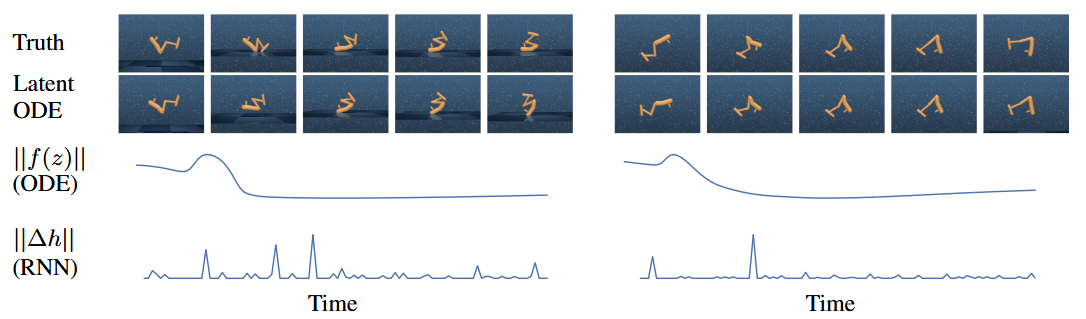

Figure and Table embedded from Rubanova et. al., 2019
*Figure 6: Top row: True trajectories from MuJoCo dataset. Second row: Trajectories reconstructed
by a latent ODE model. Third row: Norm of the dynamics function fθ in the latent space of the latent
ODE model. Fourth row: Norm of the hidden state of a RNN trained on the same dataset.*

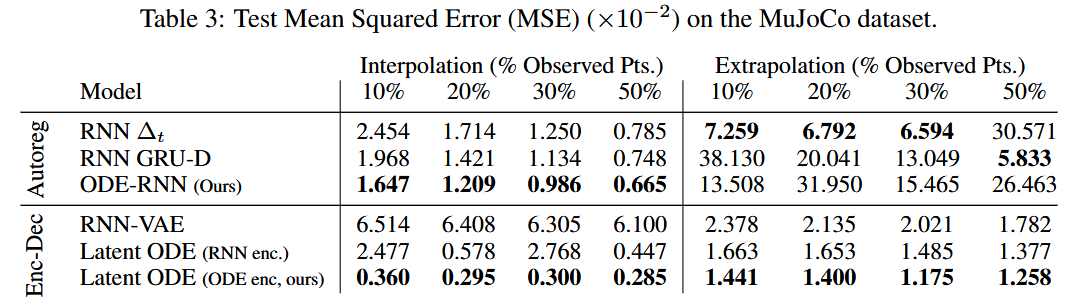

## Example 2: PhysioNEt data
* Dataset: PhysioNet Challenge 2012 dataset [Silva et al., 2012], which contains 8000 time series, each containing measurements from the first 48 hours of a different patient’s admission to ICU.
* Data for training (observations): Measurements were made at irregular times, and of varying sparse subsets of the 37 possible features.

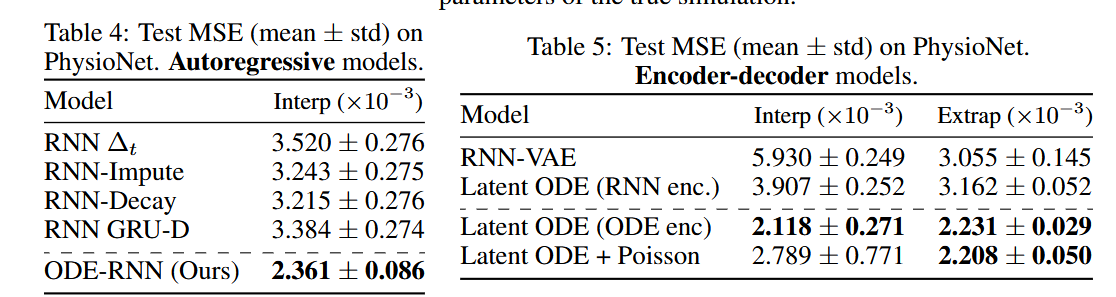

# VIII. NeuralCDE

Neural CDEs remove the need for a separate encoder/decoder by generalizing traditional ODEs to handle continuous, time-varying input signals (called "controls").

Mechanism: Rather than reducing time-series observations to a single starting point, Neural CDEs treat the observed data points as a continuous, interpolated curve (or path) X(t).

The hidden state z(t) is controlled directly by the derivative of this data path.

Core Equation: Governed by a controlled differential equation: $$dz(t) = f_\theta(z(t))dX(t)$$, where dX(t) encapsulates the continuous input data.

The hidden state $z(t)$ then evolves according to

$$ z(t) = z(t_0) + \int_{t_0}^{t} f_\theta(z(s))\, dX(s) $$

This makes it naturally suited to **irregularly-sampled time series** (missed reports,
weekends, irregular testing, etc.) and lets us query the prediction at *any* continuous time,
not just at fixed observation times.

Strengths: Highly expressive for classification and continuous forecasting tasks, as the hidden state instantly responds to incoming data. It avoids the computational overhead of training a VAE's encoder/decoder and variational distributions.

Limitations: Less suited for purely generative tasks, latent-space sampling, or capturing stochastic uncertainty without further extensions (like Neural SDEs)

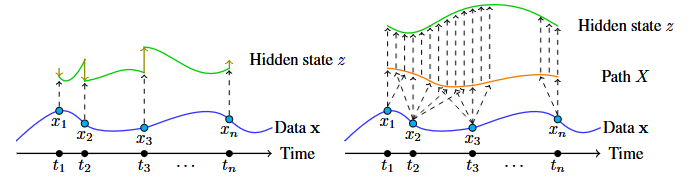

Figure embedded from * Kidger, P. et al., Neural Controlled Differential Equations for Irregular Time Series, 2020

*Figure 1: Some data process is observed at times $t_1, . . . , t_n$ to give observations $x_1, . . . , x_n$. It is
otherwise unobserved. Left: Previous work has typically modified hidden state at each observation,
and perhaps continuously evolved the hidden state between observations. Right: In contrast, the
hidden state of the Neural CDE model has continuous dependence on the observed data.*

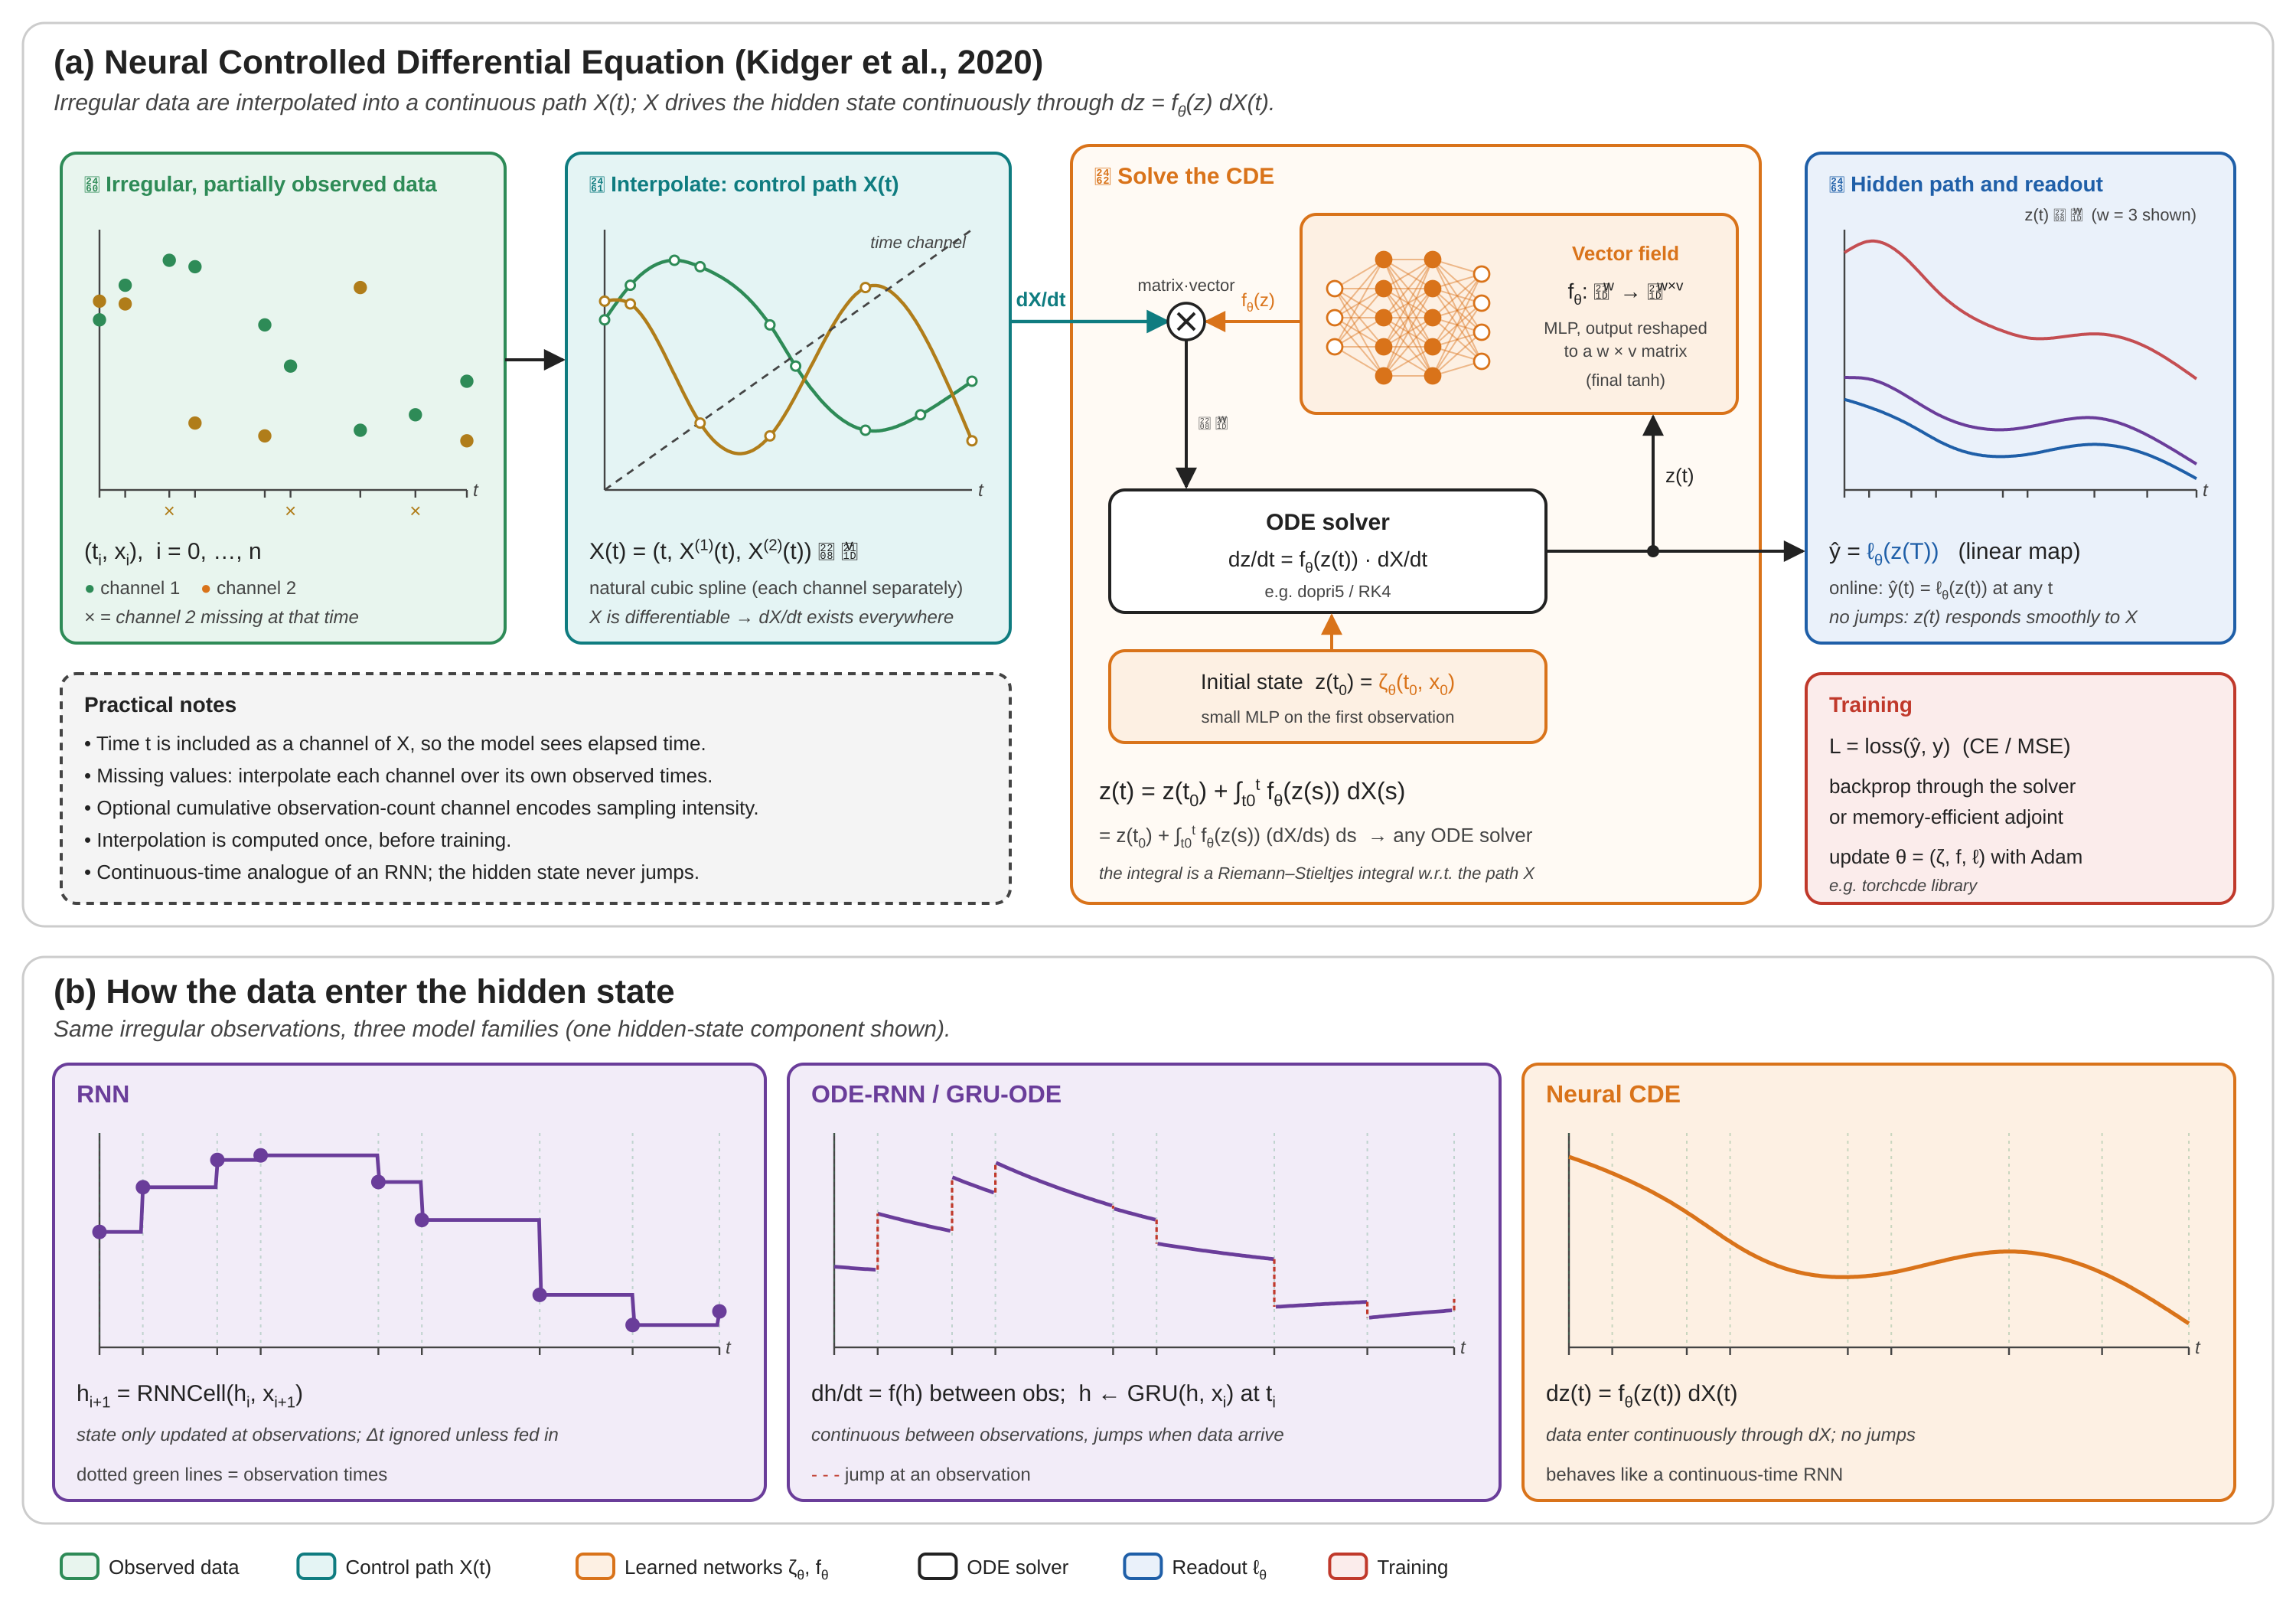

In [6]:
# @title Neural CDE (Kidger et al., 2020) figure
import re, html
import numpy as np

W, H = 1500, 1045
FONT = "Arial, Helvetica, Liberation Sans, DejaVu Sans, sans-serif"
BLUE, BLUE_BG = "#1f5fa8", "#eaf1fa"
ORANGE, ORANGE_BG = "#d9731a", "#fdf0e3"
PURPLE, PURPLE_BG = "#6a3d9a", "#f2ecf8"
RED, RED_BG = "#c0392b", "#fbeceb"
GREEN, GREEN_BG = "#2e8b57", "#e8f5ee"
GRAY, GRAY_BG = "#444", "#f4f4f4"
TEAL, TEAL_BG = "#0f7c80", "#e4f4f4"
INK = "#222"

out = []
def add(s): out.append(s)

def rich(s, size):
    """Mini markup: _{sub}, ^{sup}, [o]orange[/], [b]blue[/], [p]purple[/], [r]red[/], [g]green[/]."""
    toks = re.split(r'(_\{[^}]*\}|\^\{[^}]*\}|\[[obrgpt]\]|\[/\])', s)
    colors = {'o': ORANGE, 'b': BLUE, 'r': RED, 'g': GREEN, 'p': PURPLE, 't': TEAL}
    res, pend, col = [], 0.0, None
    for t in toks:
        if not t: continue
        if re.fullmatch(r'\[[obrgpt]\]', t): col = colors[t[1]]; continue
        if t == '[/]': col = None; continue
        fill = f' fill="{col}"' if col else ''
        if t.startswith('_{') or t.startswith('^{'):
            d = 0.28*size if t[0] == '_' else -0.38*size
            res.append(f'<tspan dy="{pend+d:.1f}" font-size="{0.68*size:.1f}"{fill}>{html.escape(t[2:-1])}</tspan>')
            pend = -d
        else:
            res.append(f'<tspan dy="{pend:.1f}"{fill}>{html.escape(t)}</tspan>')
            pend = 0.0
    return ''.join(res)

def text(x, y, s, size=15, anchor="start", weight="normal", color=INK, style="normal"):
    add(f'<text x="{x}" y="{y}" font-size="{size}" text-anchor="{anchor}" font-weight="{weight}" '
        f'font-style="{style}" fill="{color}">{rich(s, size)}</text>')

def box(x, y, w, h, stroke, fill, r=10, sw=2, dash=None):
    d = f' stroke-dasharray="{dash}"' if dash else ''
    add(f'<rect x="{x}" y="{y}" width="{w}" height="{h}" rx="{r}" fill="{fill}" stroke="{stroke}" stroke-width="{sw}"{d}/>')

def arrow(pts, color=INK, sw=2, dash=None, head=True, halo=False):
    d = f' stroke-dasharray="{dash}"' if dash else ''
    p = " ".join(f"{x:.1f},{y:.1f}" for x, y in pts)
    if halo:  # white underlay -> visible gap where this line crosses an earlier one
        add(f'<polyline points="{p}" fill="none" stroke="#fff" stroke-width="{sw+6}" stroke-linejoin="round"/>')
    m = f' marker-end="url(#ah-{color[1:]})"' if head else ''
    add(f'<polyline points="{p}" fill="none" stroke="{color}" stroke-width="{sw}" stroke-linejoin="round"{d}{m}/>')

def circle(x, y, r, stroke, fill, sw=2):
    add(f'<circle cx="{x}" cy="{y}" r="{r}" fill="{fill}" stroke="{stroke}" stroke-width="{sw}"/>')

def op(x, y, sym, color=PURPLE, r=11):
    """Pointwise operation node (⊙, +)."""
    circle(x, y, r, color, "#fff", 1.8)
    if sym == "x":
        add(f'<line x1="{x-5.5}" y1="{y-5.5}" x2="{x+5.5}" y2="{y+5.5}" stroke="{color}" stroke-width="2"/>')
        add(f'<line x1="{x-5.5}" y1="{y+5.5}" x2="{x+5.5}" y2="{y-5.5}" stroke="{color}" stroke-width="2"/>')
    else:
        add(f'<line x1="{x-6}" y1="{y}" x2="{x+6}" y2="{y}" stroke="{color}" stroke-width="2"/>')
        add(f'<line x1="{x}" y1="{y-6}" x2="{x}" y2="{y+6}" stroke="{color}" stroke-width="2"/>')

def gate(cx, cy, label, w=46, h=32, color=PURPLE):
    box(cx-w/2, cy-h/2, w, h, color, color, r=5, sw=1.5)
    text(cx, cy+5, label, 14, anchor="middle", weight="bold", color="#fff")

def nn(x, y, w, h, layers=(2, 4, 4, 2), color=ORANGE):
    xs = np.linspace(x+12, x+w-12, len(layers))
    pos = []
    for lx, n in zip(xs, layers):
        ys = np.linspace(y+h/2-(n-1)*h/(2*max(layers)), y+h/2+(n-1)*h/(2*max(layers)), n) if n > 1 else [y+h/2]
        pos.append([(lx, ly) for ly in ys])
    for a, b in zip(pos[:-1], pos[1:]):
        for p in a:
            for q in b:
                add(f'<line x1="{p[0]:.1f}" y1="{p[1]:.1f}" x2="{q[0]:.1f}" y2="{q[1]:.1f}" stroke="{color}" stroke-opacity="0.45" stroke-width="1"/>')
    for li, layer in enumerate(pos):
        for p in layer:
            f = "#fff" if li in (0, len(pos)-1) else color
            circle(round(p[0], 1), round(p[1], 1), 5, color, f, 1.4)

def ode_curve(x0, x1, y, amp=14, dashed=False, color=ORANGE, head=True):
    """Continuous trajectory with solver-step dots (x1 < x0 draws it right-to-left)."""
    xs = np.linspace(x0, x1, 60)
    ys = y - amp*np.sin(np.linspace(0, 2.2*np.pi, 60)) * np.linspace(1, 0.15, 60)
    arrow(list(zip(xs, ys)), color=color, sw=2.4, dash="6,4" if dashed else None, head=head)
    for k in range(6, 54, 9):
        circle(round(xs[k], 1), round(ys[k], 1), 3, color, color, 1)

# ---------- data for the mini-plots ----------
from scipy.interpolate import CubicSpline
rng = np.random.default_rng(7)
T_OBS = np.array([0.0, 0.07, 0.19, 0.26, 0.45, 0.52, 0.71, 0.86, 1.0])          # irregular times
X1 = 0.55 + 0.35*np.sin(2*np.pi*0.9*T_OBS + 0.3) + 0.04*rng.normal(size=9)    # channel 1
X2 = 0.45 + 0.30*np.cos(2*np.pi*1.4*T_OBS) + 0.04*rng.normal(size=9)          # channel 2
MISS2 = np.array([False, False, True, False, False, True, False, True, False])  # missing in channel 2
TT = np.linspace(0, 1, 300)
S1 = CubicSpline(T_OBS, X1, bc_type="natural")
S2 = CubicSpline(T_OBS[~MISS2], X2[~MISS2], bc_type="natural")

# a tiny (random) neural CDE driven by X = (t, X1, X2): dz = tanh(A z + b) . dX
w, v = 3, 3
A = rng.normal(0, 0.8, size=(w*v, w)); b = rng.normal(0, 0.6, size=w*v)
def dXdt(t): return np.array([1.0, S1(t, 1), S2(t, 1)])
Z = np.zeros((len(TT), w)); Z[0] = np.tanh(rng.normal(0, 0.8, size=w))
for k in range(1, len(TT)):
    dt = TT[k]-TT[k-1]
    F = np.tanh(A @ Z[k-1] + b).reshape(w, v)
    Z[k] = Z[k-1] + dt * (F @ dXdt(TT[k-1])) * 0.6

C1, C2 = "#2e8b57", "#b07d1a"        # channel colours
ZC = ["#1f5fa8", "#c44e52", "#6a3d9a"]

def plot_area(x, y, w_, h_, xlabel="t"):
    add(f'<line x1="{x}" y1="{y+h_}" x2="{x+w_}" y2="{y+h_}" stroke="{GRAY}" stroke-width="1.2"/>')
    add(f'<line x1="{x}" y1="{y}" x2="{x}" y2="{y+h_}" stroke="{GRAY}" stroke-width="1.2"/>')
    text(x+w_+4, y+h_+4, xlabel, 12, style="italic", color=GRAY)

def line(x, y, w_, h_, ts_, vs, lo, hi, color, sw=2.2, dash=None):
    px = x + ts_*w_; py = y + h_ - (np.asarray(vs)-lo)/(hi-lo)*h_
    d = f' stroke-dasharray="{dash}"' if dash else ''
    add(f'<polyline points="{" ".join(f"{a:.1f},{c:.1f}" for a, c in zip(px, py))}" fill="none" stroke="{color}" stroke-width="{sw}"{d}/>')

def dots(x, y, w_, h_, ts_, vs, lo, hi, color, r=3.6, hollow=False):
    for a, c in zip(ts_, vs):
        px, py = x + a*w_, y + h_ - (c-lo)/(hi-lo)*h_
        circle(round(px, 1), round(py, 1), r, color, "#fff" if hollow else color, 1.5)

def ticks(x, y, w_, h_, ts_):
    for a in ts_:
        add(f'<line x1="{x+a*w_:.1f}" y1="{y+h_}" x2="{x+a*w_:.1f}" y2="{y+h_+5}" stroke="{GRAY}" stroke-width="1.2"/>')

# ---------- header ----------
add(f'<svg xmlns="http://www.w3.org/2000/svg" xml:space="preserve" width="{W}" height="{H}" viewBox="0 0 {W} {H}" font-family="{FONT}">')
add('<defs>')
for c in [INK, RED, BLUE, ORANGE, GREEN, GRAY, PURPLE, TEAL]:
    add(f'<marker id="ah-{c[1:]}" viewBox="0 0 10 10" refX="9" refY="5" markerWidth="7" markerHeight="7" orient="auto-start-reverse">'
        f'<path d="M0,0 L10,5 L0,10 z" fill="{c}"/></marker>')
add('</defs>')
add(f'<rect width="{W}" height="{H}" fill="#fff"/>')

# =================== PANEL (a) pipeline ===================
add(f'<rect x="15" y="15" width="{W-30}" height="590" rx="14" fill="none" stroke="#ccc" stroke-width="1.5"/>')
text(35, 48, "(a) Neural Controlled Differential Equation (Kidger et al., 2020)", 22, weight="bold")
text(35, 72, "Irregular data are interpolated into a continuous path X(t); X drives the hidden state continuously through dz = f_{θ}(z) dX(t).", 15, color=GRAY, style="italic")

# ① data
box(40, 100, 290, 320, GREEN, GREEN_BG)
text(55, 125, "① Irregular, partially observed data", 14, weight="bold", color=GREEN)
px, py, pw, ph = 65, 150, 240, 170
plot_area(px, py, pw, ph); ticks(px, py, pw, ph, T_OBS)
dots(px, py, pw, ph, T_OBS, X1, 0, 1, C1)
dots(px, py, pw, ph, T_OBS[~MISS2], X2[~MISS2], 0, 1, C2)
for a in T_OBS[MISS2]:
    cx, cy = px + a*pw, py + ph + 18
    text(round(cx, 1), cy, "×", 13, anchor="middle", color=C2)
text(55, 365, "(t_{i}, x_{i}),  i = 0, …, n", 15)
text(55, 388, "[g]●[/] channel 1    [o]●[/] channel 2", 12, color=GRAY)
text(55, 407, "× = channel 2 missing at that time", 12, color=GRAY, style="italic")

arrow([(330, 235), (368, 235)], color=INK)

# ② interpolation
box(370, 100, 290, 320, TEAL, TEAL_BG)
text(385, 125, "② Interpolate: control path X(t)", 14, weight="bold", color=TEAL)
qx = 395
plot_area(qx, py, pw, ph)
line(qx, py, pw, ph, TT, S1(TT), 0, 1, C1)
line(qx, py, pw, ph, TT, S2(TT), 0, 1, C2)
line(qx, py, pw, ph, TT, TT, 0, 1, GRAY, sw=1.4, dash="5,4")
dots(qx, py, pw, ph, T_OBS, X1, 0, 1, C1, r=3, hollow=True)
dots(qx, py, pw, ph, T_OBS[~MISS2], X2[~MISS2], 0, 1, C2, r=3, hollow=True)
text(qx+pw-4, py+12, "time channel", 11, anchor="end", color=GRAY, style="italic")
text(385, 365, "X(t) = (t, X^{(1)}(t), X^{(2)}(t)) ∈ ℝ^{v}", 15)
text(385, 388, "natural cubic spline (each channel separately)", 12, color=GRAY)
text(385, 407, "X is differentiable → dX/dt exists everywhere", 12, color=GRAY, style="italic")

# ③ CDE solve
cx0, cy0, cx1, cy1 = 700, 95, 1150, 590
box(cx0, cy0, cx1-cx0, cy1-cy0, ORANGE, "#fffaf4", r=12)
text(cx0+15, cy0+25, "③ Solve the CDE", 15, weight="bold", color=ORANGE)

MX, MY = 775, 210           # ⊗ node: f_θ(z) · dX/dt
arrow([(660, MY), (MX-12, MY)], color=TEAL, sw=2.2)
text(680, MY-10, "dX/dt", 13, anchor="middle", color=TEAL, weight="bold")

box(850, 140, 285, 130, ORANGE, ORANGE_BG)
nn(860, 160, 120, 95, layers=(3, 5, 5, 4))
text(1062, 170, "Vector field", 13, anchor="middle", weight="bold", color=ORANGE)
text(1062, 195, "f_{θ}: ℝ^{w} → ℝ^{w×v}", 14, anchor="middle")
text(1062, 218, "MLP, output reshaped", 11, anchor="middle", color=GRAY)
text(1062, 233, "to a w × v matrix", 11, anchor="middle", color=GRAY)
text(1062, 252, "(final tanh)", 11, anchor="middle", color=GRAY)
arrow([(850, MY), (MX+13, MY)], color=ORANGE)
text(822, MY-10, "f_{θ}(z)", 12, anchor="middle", color=ORANGE)
op(MX, MY, "x", color=INK, r=12)
text(MX, MY-20, "matrix·vector", 11, anchor="middle", color=GRAY)

SX0, SY0, SX1, SY1 = 725, 320, 1010, 400
box(SX0, SY0, SX1-SX0, SY1-SY0, INK, "#fff")
text((SX0+SX1)/2, SY0+26, "ODE solver", 15, anchor="middle", weight="bold")
text((SX0+SX1)/2, SY0+50, "dz/dt = f_{θ}(z(t)) · dX/dt", 14, anchor="middle")
text((SX0+SX1)/2, SY0+70, "e.g. dopri5 / RK4", 11, anchor="middle", color=GRAY)
arrow([(MX, MY+12), (MX, SY0-2)], color=INK)
text(MX+8, 280, "∈ ℝ^{w}", 11, color=GRAY)

# feedback z(t) -> f_θ  and branch to readout
JX = 1080
arrow([(SX1, 360), (JX, 360), (JX, 272)], color=INK)
circle(JX, 360, 3.5, INK, INK, 1)
text(JX+8, 315, "z(t)", 13, color=INK)

# initial condition network
box(SX0, 425, SX1-SX0, 60, ORANGE, ORANGE_BG)
text((SX0+SX1)/2, 450, "Initial state  z(t_{0}) = [o]ζ_{θ}(t_{0}, x_{0})[/]", 14, anchor="middle")
text((SX0+SX1)/2, 472, "small MLP on the first observation", 11, anchor="middle", color=GRAY)
arrow([(870, 425), (870, SY1+2)], color=ORANGE)

text(cx0+18, 522, "z(t) = z(t_{0}) + ∫_{t0}^{t} f_{θ}(z(s)) dX(s)", 16)
text(cx0+18, 550, "= z(t_{0}) + ∫_{t0}^{t} f_{θ}(z(s)) (dX/ds) ds  → any ODE solver", 13, color=GRAY)
text(cx0+18, 574, "the integral is a Riemann–Stieltjes integral w.r.t. the path X", 11, color=GRAY, style="italic")

# ④ readout
arrow([(JX, 360), (1178, 360)], color=INK)
box(1180, 100, 280, 320, BLUE, BLUE_BG)
text(1195, 125, "④ Hidden path and readout", 14, weight="bold", color=BLUE)
rx_, rw_ = 1205, 230
zlo, zhi = Z.min()-0.05, Z.max()+0.05
plot_area(rx_, py, rw_, ph); ticks(rx_, py, rw_, ph, T_OBS)
for k in range(w):
    line(rx_, py, rw_, ph, TT, Z[:, k], zlo, zhi, ZC[k], sw=2)
text(rx_+rw_, py-6, "z(t) ∈ ℝ^{w}  (w = 3 shown)", 11, anchor="end", color=GRAY)
text(1195, 365, "ŷ = [b]ℓ_{θ}(z(T))[/]   (linear map)", 15)
text(1195, 388, "online: ŷ(t) = ℓ_{θ}(z(t)) at any t", 12, color=GRAY)
text(1195, 407, "no jumps: z(t) responds smoothly to X", 12, color=GRAY, style="italic")

# notes + training
box(40, 440, 620, 150, GRAY, GRAY_BG, dash="5,4")
text(55, 465, "Practical notes", 14, weight="bold")
for k, s_ in enumerate([
        "• Time t is included as a channel of X, so the model sees elapsed time.",
        "• Missing values: interpolate each channel over its own observed times.",
        "• Optional cumulative observation-count channel encodes sampling intensity.",
        "• Interpolation is computed once, before training.",
        "• Continuous-time analogue of an RNN; the hidden state never jumps."]):
    text(55, 490+k*21, s_, 13)
box(1180, 440, 280, 150, RED, RED_BG)
text(1195, 465, "Training", 14, weight="bold", color=RED)
text(1195, 492, "L = loss(ŷ, y)  (CE / MSE)", 14)
text(1195, 518, "backprop through the solver", 13)
text(1195, 538, "or memory-efficient adjoint", 13)
text(1195, 564, "update θ = (ζ, f, ℓ) with Adam", 13)
text(1195, 582, "e.g. torchcde library", 11, color=GRAY, style="italic")

# =================== PANEL (b) comparison ===================
oy = 625
add(f'<rect x="15" y="{oy}" width="{W-30}" height="370" rx="14" fill="none" stroke="#ccc" stroke-width="1.5"/>')
text(35, oy+30, "(b) How the data enter the hidden state", 22, weight="bold")
text(35, oy+52, "Same irregular observations, three model families (one hidden-state component shown).", 15, color=GRAY, style="italic")

# hidden trajectories for the three families
def rnn_traj():
    h, out_ = 0.2, []
    vals = []
    for i in range(len(T_OBS)):
        h = np.tanh(0.6*h + 1.1*X1[i] - 0.4)
        vals.append(h)
    idx = np.searchsorted(T_OBS, TT, side="right") - 1
    return np.array(vals)[idx], np.array(vals)
def odernn_traj():
    out_, h, j = [], 0.0, 0
    hs = []
    for k, t in enumerate(TT):
        while j < len(T_OBS) and t >= T_OBS[j]:
            h = 0.5*h + 0.6*(X1[j]-0.3); j += 1
        if k: h = h + (TT[k]-TT[k-1])*(-2.2*h + 0.3)
        out_.append(h)
    return np.array(out_)
r_line, r_pts = rnn_traj()
o_line = odernn_traj()
c_line = Z[:, 0]

panels = [
    ("RNN", PURPLE, "h_{i+1} = RNNCell(h_{i}, x_{i+1})",
     "state only updated at observations; Δt ignored unless fed in"),
    ("ODE-RNN / GRU-ODE", PURPLE, "dh/dt = f(h) between obs;  h ← GRU(h, x_{i}) at t_{i}",
     "continuous between observations, jumps when data arrive"),
    ("Neural CDE", ORANGE, "dz(t) = f_{θ}(z(t)) dX(t)",
     "data enter continuously through dX; no jumps"),
]
for k, (name, col, eq, note) in enumerate(panels):
    bx = 35 + k*480
    box(bx, oy+70, 465, 285, col, PURPLE_BG if col == PURPLE else ORANGE_BG)
    text(bx+15, oy+95, name, 16, weight="bold", color=col)
    gx, gy_, gw_, gh_ = bx+30, oy+115, 405, 140
    # faint data path underneath
    plot_area(gx, gy_, gw_, gh_); ticks(gx, gy_, gw_, gh_, T_OBS)
    for a in T_OBS:
        add(f'<line x1="{gx+a*gw_:.1f}" y1="{gy_}" x2="{gx+a*gw_:.1f}" y2="{gy_+gh_}" stroke="{GREEN}" stroke-opacity="0.25" stroke-width="1" stroke-dasharray="2,3"/>')
    if k == 0:
        lo, hi = r_line.min()-0.1, r_line.max()+0.1
        line(gx, gy_, gw_, gh_, TT, r_line, lo, hi, col, sw=2.4)
        dots(gx, gy_, gw_, gh_, T_OBS, r_pts, lo, hi, col, r=4)
    elif k == 1:
        lo, hi = o_line.min()-0.1, o_line.max()+0.1
        # draw segments separately so jumps show as gaps
        idx = np.searchsorted(T_OBS, TT, side="right") - 1
        for seg in range(len(T_OBS)):
            m = idx == seg
            if m.sum() > 1:
                line(gx, gy_, gw_, gh_, TT[m], o_line[m], lo, hi, col, sw=2.4)
        for a in T_OBS[1:]:
            j0 = np.searchsorted(TT, a) - 1
            if 0 <= j0 < len(TT)-1:
                x_ = gx + a*gw_
                y_a = gy_ + gh_ - (o_line[j0]-lo)/(hi-lo)*gh_
                y_b = gy_ + gh_ - (o_line[j0+1]-lo)/(hi-lo)*gh_
                add(f'<line x1="{x_:.1f}" y1="{y_a:.1f}" x2="{x_:.1f}" y2="{y_b:.1f}" stroke="{RED}" stroke-width="1.6" stroke-dasharray="3,2"/>')
    else:
        lo, hi = c_line.min()-0.05, c_line.max()+0.05
        line(gx, gy_, gw_, gh_, TT, c_line, lo, hi, col, sw=2.6)
    text(bx+15, oy+290, eq, 15)
    text(bx+15, oy+316, note, 12, color=GRAY, style="italic")
text(35+480+15, oy+342, "[r]- - -[/] jump at an observation", 12, color=GRAY)
text(35+15, oy+342, "dotted green lines = observation times", 12, color=GRAY)
text(35+960+15, oy+342, "behaves like a continuous-time RNN", 12, color=GRAY)

# =================== legend ===================
ly0 = 1015
items = [(GREEN, GREEN_BG, "Observed data"), (TEAL, TEAL_BG, "Control path X(t)"),
         (ORANGE, ORANGE_BG, "Learned networks ζ_{θ}, f_{θ}"), (INK, "#fff", "ODE solver"),
         (BLUE, BLUE_BG, "Readout ℓ_{θ}"), (RED, RED_BG, "Training")]
x = 40
for st, fi, lab in items:
    box(x, ly0, 24, 16, st, fi, r=4)
    text(x+31, ly0+13, lab, 13)
    x += 31 + len(re.sub(r'[_{}]', '', lab))*6.9 + 34

add('</svg>')
svg_str = "\n".join(out)

# ---------- render to PNG and display (Colab; also shows on GitHub after saving) ----------
import shutil, subprocess
from IPython.display import Image, SVG, display

with open("neural_cde.svg", "w", encoding="utf-8") as f:
    f.write(svg_str)

if shutil.which("rsvg-convert") is None:          # Colab: install the SVG renderer once
    subprocess.run("apt-get -qq install -y librsvg2-bin > /dev/null", shell=True)

if shutil.which("rsvg-convert"):
    subprocess.run(["rsvg-convert", "-z", "2", "neural_cde.svg", "-o", "neural_cde.png"], check=True)
    display(Image("neural_cde.png", width=1000))
else:                                              # fallback: browser renders the SVG
    display(SVG(svg_str))


---

# IX Summary Reference Table

| Model | Latent State Evolution ($\mathbf{z}_t$ or $\mathbf{h}_t$) | How Observations $\mathbf{x}_i$ / Path $\mathbf{X}_t$ Enter |
| :--- | :--- | :--- |
| **Autonomous NODE** | $\mathbf{z}_t = \mathbf{z}_{t_0} + \int_{t_0}^t f_\theta(\mathbf{z}_s)\,ds$ | Only at the initial condition $\mathbf{z}_{t_0} = \ell_\theta(\mathbf{x}_0)$. |
| **Non-autonomous NODE** | $\mathbf{z}_t = \mathbf{z}_{t_0} + \int_{t_0}^t f_\theta(\mathbf{z}_s, \mathbf{X}_s)\,ds$ | Fed directly as an explicit time-varying input to $f_\theta$. |
| **ODE-RNN** | $\mathbf{h}'_i = \text{ODESolve}(f_\theta, \mathbf{h}_{i-1}, (t_{i-1}, t_i))$ <br> $\mathbf{h}_i = \text{RNNCell}(\mathbf{h}'_i, \mathbf{x}_i)$ | Discrete jumps at each observation time $t_i$ via an RNN update. |
| **Latent ODE** | $\mathbf{z}_0 \sim q_\phi(\mathbf{z}_0 \mid \{\mathbf{x}_i, t_i\}_{i=0}^n)$ <br> $\mathbf{z}_t = \mathbf{z}_0 + \int_{t_0}^t f_\theta(\mathbf{z}_s)\,ds$ | Aggregated backward by an ODE-RNN encoder to infer the posterior over $\mathbf{z}_0$. |
| **Neural CDE** | $\mathbf{z}_t = \mathbf{z}_{t_0} + \int_{t_0}^t f_\theta(\mathbf{z}_s)\,d\mathbf{X}_s = \mathbf{z}_{t_0} + \int_{t_0}^t f_\theta(\mathbf{z}_s)\frac{d\mathbf{X}_s}{ds}\,ds$ | Continuously drives the vector field via the derivative $\frac{d\mathbf{X}_s}{ds}$ of the interpolated path $\mathbf{X}_t = (\mathbf{x}_t, t)$. |

*(Note: If you also have separate exogenous control interventions alongside observed state outputs—such as policy interventions $\mathbf{u}_t$ distinct from measured outcomes $\mathbf{x}_i$—you can concatenate both into the driving path $\mathbf{X}_t = (\mathbf{x}_t, \mathbf{u}_t, t)$ in Neural CDEs or pass $\mathbf{u}_t$ alongside $\mathbf{x}_i$ into the encoder/dynamics.)*


## X. Future directions:

Morill, et. al., Neural Controlled Differential Equations for
Online Prediction Tasks,2021 https://arxiv.org/pdf/2106.11028

**Review articles**
* Oh et. al., Comprehensive review of neural differential equations for time series analysis, IJCAI '25: Proceedings of the Thirty-Fourth International Joint Conference on Artificial Intelligence Article No.: 1179, Pages 10621 - 10631
https://doi.org/10.24963/ijcai.2025/11 arXiv:
https://arxiv.org/html/2502.09885v1#abstract1
* Worsham, J., and Kalita, J., A guide to neural ordinary differential equations: Machine learning for data-driven digital engineering, Digital Engineering
Volume 6, September 2025, https://doi.org/10.1016/j.dte.2025.100060